# InspectData

In [3]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits

print('Libraries imported successfully')

Libraries imported successfully


## Load KiDs Data

In [4]:
kids_fits_file = "/DATA02/rhoffmann/KiDs/KiDS_Legacy_NS_unblind_final.fits.gz"
fits_files = [kids_fits_file]
kids_hdul = fits.open(kids_fits_file)
kids_data = kids_hdul[1].data
print(f'Loaded KiDS data from {kids_fits_file}')
print('Shape:', kids_data.shape)

Loaded KiDS data from /DATA02/rhoffmann/KiDs/KiDS_Legacy_NS_unblind_final.fits.gz
Shape: (40894394,)


In [5]:
#kids_df = pd.DataFrame(kids_data[:10])
#display(kids_df.head(10))

In [6]:
kids_rows_before_filter = len(kids_data)
kids_data = kids_data[kids_data['DECJ2000'] >= -15]
kids_df = pd.DataFrame(kids_data)

print(f'KiDS rows removed with DEC < -15 deg: {kids_rows_before_filter - len(kids_data):,}')
print(f'KiDS rows remaining: {len(kids_data):,}')
print(f'KiDS DataFrame shape: {kids_df.shape}')

KiDS rows removed with DEC < -15 deg: 20,423,231
KiDS rows remaining: 20,471,163
KiDS DataFrame shape: (20471163, 50)


## Display KiDs Data

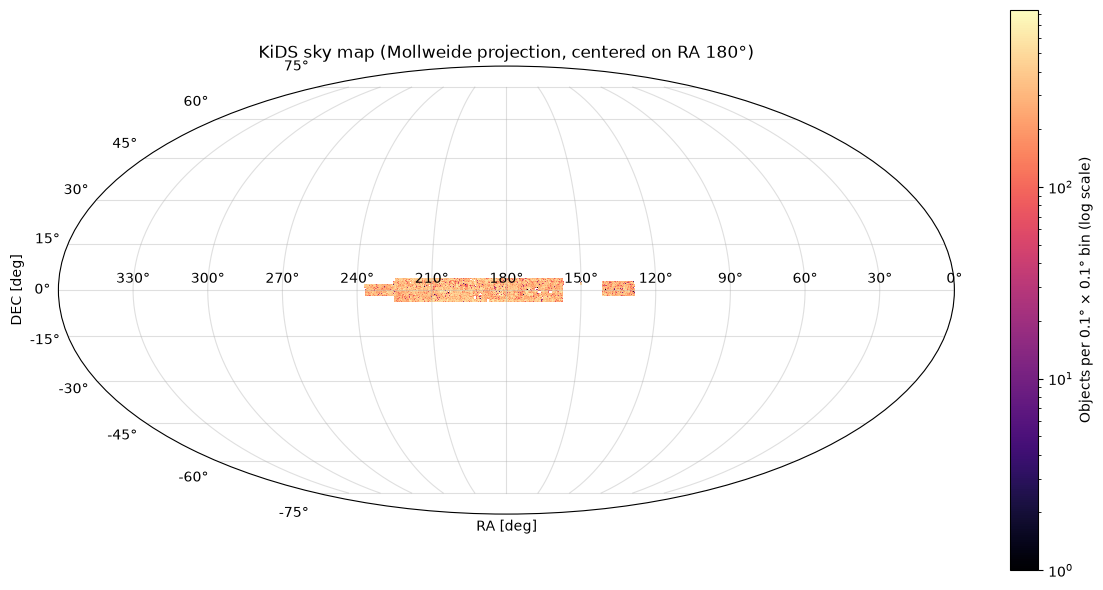

In [7]:
from matplotlib.colors import LogNorm

ra_bins = np.linspace(-180, 180, 3601)
dec_bins = np.linspace(-90, 90, 1801)
counts = np.zeros((len(ra_bins) - 1, len(dec_bins) - 1), dtype=np.int64)

for start in range(0, len(kids_data), 1_000_000):
    chunk = kids_data[start:start + 1_000_000]
    ra_longitude = -((chunk['RAJ2000'] % 360) - 180)
    counts += np.histogram2d(
        ra_longitude,
        chunk['DECJ2000'],
        bins=(ra_bins, dec_bins),
    )[0].astype(np.int64)

fig, ax = plt.subplots(figsize=(12, 6), subplot_kw={'projection': 'mollweide'})
image = ax.pcolormesh(
    np.radians(ra_bins),
    np.radians(dec_bins),
    np.ma.masked_less_equal(counts.T, 0),
    norm=LogNorm(vmin=1),
    cmap='magma',
    shading='auto',
)
ra_ticks = np.arange(-150, 181, 30)
ax.set_xticks(np.radians(ra_ticks))
ax.set_xticklabels([f'{int((180 - ra) % 360)}°' for ra in ra_ticks])
ax.set_xlabel('RA [deg]')
ax.set_ylabel('DEC [deg]')
ax.grid(True, alpha=0.4)
ax.set_title('KiDS sky map (Mollweide projection, centered on RA 180°)')
fig.colorbar(image, ax=ax, label='Objects per 0.1° × 0.1° bin (log scale)')
plt.tight_layout()
plt.show()

## Load DESI Data

In [8]:
with fits.open('/DATA02/rhoffmann/DESI/BGS ANY/BGS ANY.fits') as hdul:
    bgs_any_df = pd.DataFrame(hdul[1].data)


with fits.open('/DATA02/rhoffmann/DESI/LRG/LRG.fits') as hdul:
    lrg_df = pd.DataFrame(hdul[1].data)

print('BGS ANY:', bgs_any_df.shape)
print('LRG:', lrg_df.shape)


BGS ANY: (1027650, 18)
LRG: (515770, 13)


In [9]:
#display(bgs_any_df.head(10))

#display(lrg_df.head(10))

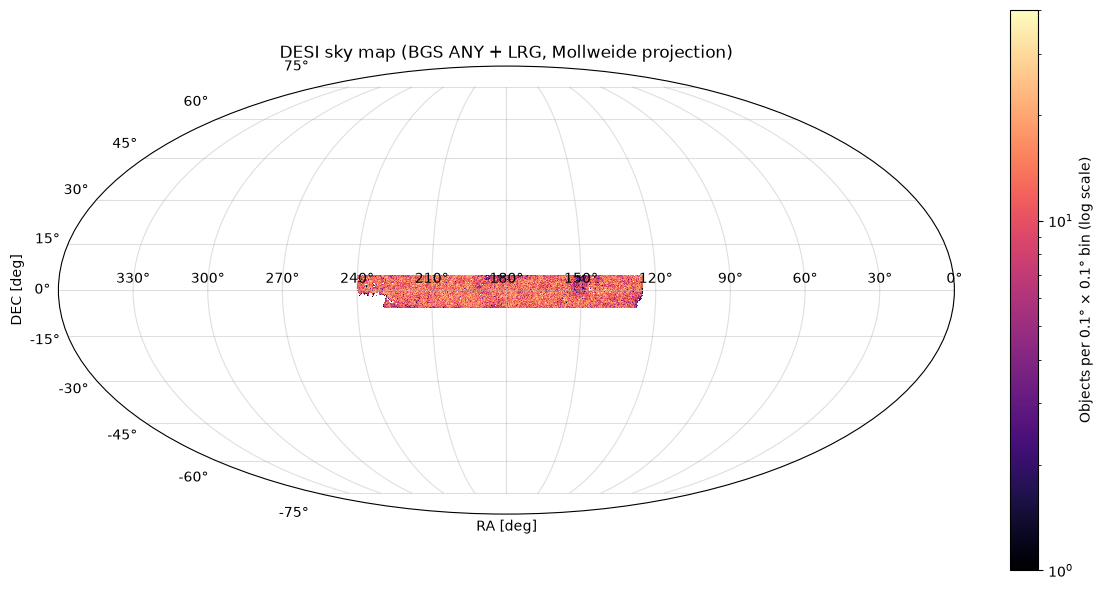

In [10]:
desi_counts = np.zeros((len(ra_bins) - 1, len(dec_bins) - 1), dtype=np.int64)

for catalog in (bgs_any_df, lrg_df):
    ra_column = next(column for column in catalog.columns if column.lower().endswith('.ra'))
    dec_column = next(column for column in catalog.columns if column.lower().endswith('.dec'))
    ra_longitude = -((catalog[ra_column].to_numpy() % 360) - 180)
    desi_counts += np.histogram2d(
        ra_longitude,
        catalog[dec_column].to_numpy(),
        bins=(ra_bins, dec_bins),
    )[0].astype(np.int64)

fig, ax = plt.subplots(figsize=(12, 6), subplot_kw={'projection': 'mollweide'})
image = ax.pcolormesh(
    np.radians(ra_bins),
    np.radians(dec_bins),
    np.ma.masked_less_equal(desi_counts.T, 0),
    norm=LogNorm(vmin=1),
    cmap='magma',
    shading='auto',
)
ra_ticks = np.arange(-150, 181, 30)
ax.set_xticks(np.radians(ra_ticks))
ax.set_xticklabels([f'{int((180 - ra) % 360)}°' for ra in ra_ticks])
ax.set_xlabel('RA [deg]')
ax.set_ylabel('DEC [deg]')
ax.grid(True, alpha=0.4)
ax.set_title('DESI sky map (BGS ANY + LRG, Mollweide projection)')
fig.colorbar(image, ax=ax, label='Objects per 0.1° × 0.1° bin (log scale)')
plt.tight_layout()
plt.show()

## Dataset Comparison

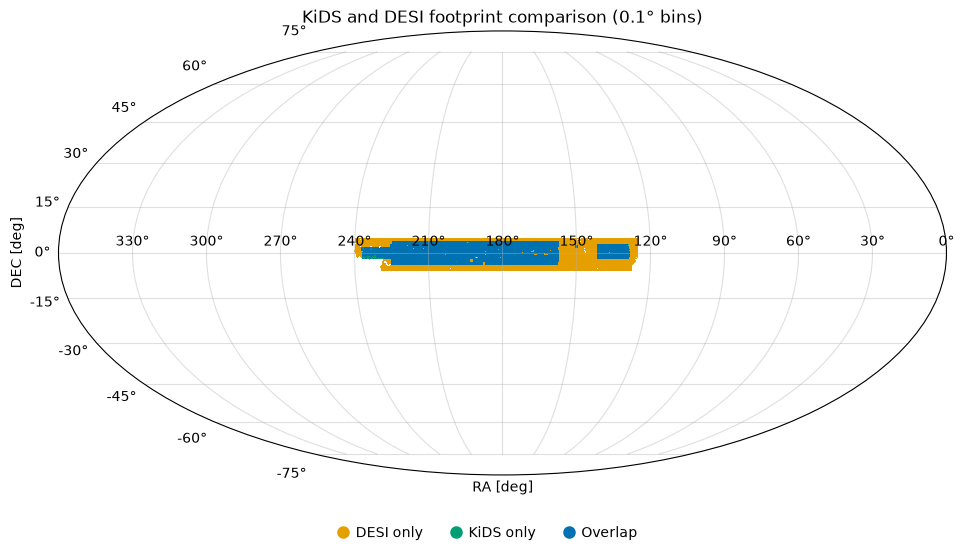

KiDS fully covered by DESI: No
Overlapping bins: 64,529
KiDS-only bins: 713
DESI-only bins: 55,367


In [11]:
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D

kids_occupied = counts > 0
desi_occupied = desi_counts > 0
shared = kids_occupied & desi_occupied
kids_only = kids_occupied & ~desi_occupied
desi_only = desi_occupied & ~kids_occupied

comparison = np.zeros_like(counts, dtype=np.uint8)
comparison[desi_only] = 1
comparison[kids_only] = 2
comparison[shared] = 3

comparison_cmap = ListedColormap(['#e69f00', '#009e73', '#0072b2'])
comparison_norm = BoundaryNorm([0.5, 1.5, 2.5, 3.5], comparison_cmap.N)

fig, ax = plt.subplots(figsize=(12, 6), subplot_kw={'projection': 'mollweide'})
ax.pcolormesh(
    np.radians(ra_bins),
    np.radians(dec_bins),
    np.ma.masked_equal(comparison.T, 0),
    cmap=comparison_cmap,
    norm=comparison_norm,
    shading='auto',
)
ra_ticks = np.arange(-150, 181, 30)
ax.set_xticks(np.radians(ra_ticks))
ax.set_xticklabels([f'{int((180 - ra) % 360)}°' for ra in ra_ticks])
ax.set_xlabel('RA [deg]')
ax.set_ylabel('DEC [deg]')
ax.grid(True, alpha=0.4)
ax.set_title('KiDS and DESI footprint comparison (0.1° bins)')

legend_items = [
    Line2D([], [], marker='o', linestyle='None', color='#e69f00', markersize=8,
           label='DESI only'),
    Line2D([], [], marker='o', linestyle='None', color='#009e73', markersize=8,
           label='KiDS only'),
    Line2D([], [], marker='o', linestyle='None', color='#0072b2', markersize=8,
           label='Overlap'),
]
fig.legend(
    handles=legend_items,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.01),
    ncol=3,
    frameon=False,
    handlelength=0.8,
    handletextpad=0.5,
)
fig.subplots_adjust(bottom=0.14)
plt.show()

print(f'KiDS fully covered by DESI: {"Yes" if not np.any(kids_only) else "No"}')
print(f'Overlapping bins: {np.count_nonzero(shared):,}')
print(f'KiDS-only bins: {np.count_nonzero(kids_only):,}')
print(f'DESI-only bins: {np.count_nonzero(desi_only):,}')

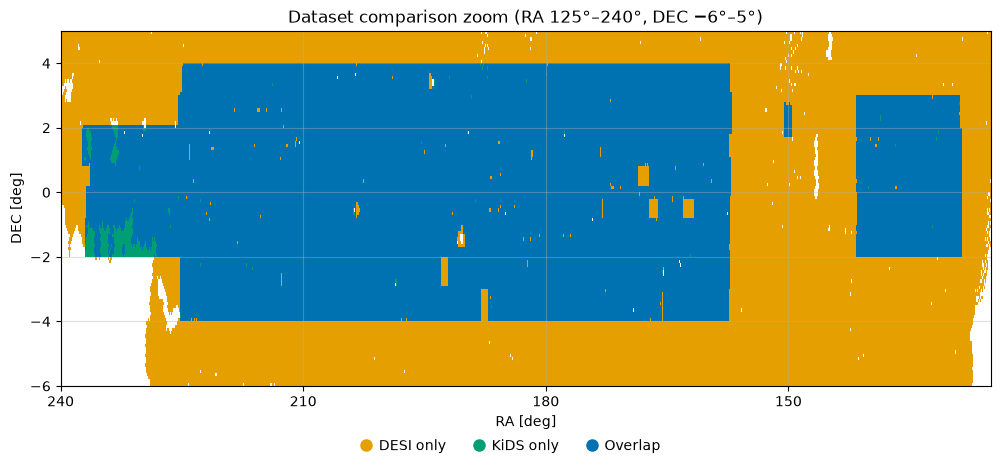

Non-empty bins in zoom: 120,609


In [12]:
ra_longitude_centers = (ra_bins[:-1] + ra_bins[1:]) / 2
ra_centers = (180 - ra_longitude_centers) % 360
dec_centers = (dec_bins[:-1] + dec_bins[1:]) / 2

ra_indices = np.flatnonzero((ra_centers >= 120) & (ra_centers <= 240))
dec_indices = np.flatnonzero((dec_centers >= -10) & (dec_centers <= 10))

zoom_ra_edges = 180 - ra_bins[ra_indices[0]:ra_indices[-1] + 2]
zoom_dec_edges = dec_bins[dec_indices[0]:dec_indices[-1] + 2]
zoom_comparison = comparison[np.ix_(ra_indices, dec_indices)]

fig, ax = plt.subplots(figsize=(12, 5))
ax.pcolormesh(
    zoom_ra_edges,
    zoom_dec_edges,
    np.ma.masked_equal(zoom_comparison.T, 0),
    cmap=comparison_cmap,
    norm=comparison_norm,
    shading='auto',
)
ax.set_xlim(240, 125)
ax.set_ylim(-6, 5)
ax.set_xticks(np.arange(240, 124, -30))
ax.set_xlabel('RA [deg]')
ax.set_ylabel('DEC [deg]')
ax.grid(True, alpha=0.4)
ax.set_title('Dataset comparison zoom (RA 125°–240°, DEC −6°–5°)')
fig.legend(
    handles=legend_items,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.01),
    ncol=3,
    frameon=False,
    handlelength=0.8,
    handletextpad=0.5,
)
fig.subplots_adjust(bottom=0.17)
plt.show()
print(f'Non-empty bins in zoom: {np.count_nonzero(zoom_comparison):,}')

In [55]:
print('KiDS columns:')
print(kids_df.columns.tolist())

print('\n--- THELI_NAME ---')
theli = kids_df['THELI_NAME'].to_numpy()
unique_theli = np.unique(theli)

print('Anzahl Objekte:', len(theli))
print('Anzahl eindeutiger THELI_NAME:', len(unique_theli))

print('\nErste 30 THELI_NAME:')
print(unique_theli[:30])

print('\n--- PATCH ---')
patch = kids_df['PATCH'].to_numpy()

patch_values, patch_counts = np.unique(patch, return_counts=True)

for value, count in zip(patch_values, patch_counts):
    print(f'{value}: {count:,} Objekte')

print('\nAnzahl eindeutiger PATCH-Werte:', len(patch_values))

KiDS columns:
['THELI_NAME', 'RAJ2000', 'DECJ2000', 'PATCH', 'Level', 'FLUX_RADIUS', 'Agaper', 'Bgaper', 'SG2DPHOT', 'MAG_AUTO', 'MAG_GAAP_u', 'MAG_GAAP_g', 'MAG_GAAP_r', 'MAG_GAAP_i1', 'MAG_GAAP_i2', 'MAG_GAAP_Z', 'MAG_GAAP_Y', 'MAG_GAAP_J', 'MAG_GAAP_H', 'MAG_GAAP_Ks', 'Z_B', 'T_B', 'TOMOBIN', 'PSF_e1', 'PSF_e2', 'PSF_Q11', 'PSF_Q22', 'PSF_Q12', 'bulge_fraction', 'pixel_SNratio', 'model_SNratio', 'autocal_scalelength_pixels', '2D_measurement_variance', 'n_exposures_used', 'delta_SNR', 'PSF_e1_exp1', 'PSF_e2_exp1', 'PSF_e1_exp2', 'PSF_e2_exp2', 'PSF_e1_exp3', 'PSF_e2_exp3', 'PSF_e1_exp4', 'PSF_e2_exp4', 'PSF_e1_exp5', 'PSF_e2_exp5', 'shear_weight_only', 'gold_weight_only', 'e1', 'e2', 'weight']

--- THELI_NAME ---
Anzahl Objekte: 20471163
Anzahl eindeutiger THELI_NAME: 672

Erste 30 THELI_NAME:
['KIDS_129p0_0p5   ' 'KIDS_129p0_1p5   ' 'KIDS_129p0_m0p5  '
 'KIDS_129p0_m1p5  ' 'KIDS_129p4_2p5   ' 'KIDS_130p0_0p5   '
 'KIDS_130p0_1p5   ' 'KIDS_130p0_m0p5  ' 'KIDS_130p0_m1p5  '
 'KIDS_130

In [56]:
# Objekte pro KiDS-Tile

tile_names, tile_counts = np.unique(theli, return_counts=True)

print('Anzahl Tiles:', len(tile_names))

print('\n10 Tiles mit den meisten Objekten:')
order = np.argsort(tile_counts)[::-1]

for i in order[:10]:
    print(f'{tile_names[i]}: {tile_counts[i]:,}')

Anzahl Tiles: 672

10 Tiles mit den meisten Objekten:
KIDS_206p0_m0p5  : 52,610
KIDS_172p0_m0p5  : 49,180
KIDS_185p5_m3p5  : 48,297
KIDS_182p0_m1p5  : 48,179
KIDS_192p5_2p5   : 47,784
KIDS_211p6_3p5   : 47,382
KIDS_182p0_m0p5  : 46,044
KIDS_228p0_m0p5  : 45,662
KIDS_203p6_m3p5  : 45,548
KIDS_170p0_m1p5  : 45,461


In [57]:
# Tile-Koordinaten mit mittleren Objektkoordinaten vergleichen
import re

for tile_value in unique_theli[:20]:
    name = str(tile_value).strip()
    match = re.fullmatch(r'KIDS_(\d+p\d+)_(m?\d+p\d+)', name)

    if match:
        ra_str, dec_str = match.groups()
        ra_tile = float(ra_str.replace('p', '.'))
        dec_tile = (
            -float(dec_str[1:].replace('p', '.'))
            if dec_str.startswith('m')
            else float(dec_str.replace('p', '.'))
        )

        mask = theli == tile_value
        ra_objects = kids_df.loc[mask, 'RAJ2000'].to_numpy()
        dec_objects = kids_df.loc[mask, 'DECJ2000'].to_numpy()

        print(
            f'{name:20s} | '
            f'Tile: RA={ra_tile:6.2f}, DEC={dec_tile:6.2f} | '
            f'Objekte: RA={np.mean(ra_objects):6.2f}, '
            f'DEC={np.mean(dec_objects):6.2f}'
        )

KIDS_129p0_0p5       | Tile: RA=129.00, DEC=  0.50 | Objekte: RA=128.97, DEC=  0.50
KIDS_129p0_1p5       | Tile: RA=129.00, DEC=  1.50 | Objekte: RA=129.01, DEC=  1.50
KIDS_129p0_m0p5      | Tile: RA=129.00, DEC= -0.50 | Objekte: RA=128.96, DEC= -0.48
KIDS_129p0_m1p5      | Tile: RA=129.00, DEC= -1.50 | Objekte: RA=128.99, DEC= -1.51
KIDS_129p4_2p5       | Tile: RA=129.40, DEC=  2.50 | Objekte: RA=129.39, DEC=  2.47
KIDS_130p0_0p5       | Tile: RA=130.00, DEC=  0.50 | Objekte: RA=130.00, DEC=  0.49
KIDS_130p0_1p5       | Tile: RA=130.00, DEC=  1.50 | Objekte: RA=130.01, DEC=  1.47
KIDS_130p0_m0p5      | Tile: RA=130.00, DEC= -0.50 | Objekte: RA=130.01, DEC= -0.51
KIDS_130p0_m1p5      | Tile: RA=130.00, DEC= -1.50 | Objekte: RA=129.99, DEC= -1.48
KIDS_130p4_2p5       | Tile: RA=130.40, DEC=  2.50 | Objekte: RA=130.35, DEC=  2.47
KIDS_131p0_0p5       | Tile: RA=131.00, DEC=  0.50 | Objekte: RA=130.96, DEC=  0.51
KIDS_131p0_1p5       | Tile: RA=131.00, DEC=  1.50 | Objekte: RA=131.00, DEC

In [58]:
# Ein einzelnes KiDS-Pointing untersuchen

tile = 'KIDS_129p0_0p5'
tile_value = next(
    (value for value in unique_theli if str(value).strip() == tile),
    None,
)

print(f'Tile: {tile}')
if tile_value is None:
    print('Tile nicht in den KiDS-Daten gefunden.')
else:
    mask = theli == tile_value
    ra = kids_df.loc[mask, 'RAJ2000'].to_numpy()
    dec = kids_df.loc[mask, 'DECJ2000'].to_numpy()

    print(f'Anzahl Objekte: {len(ra):,}')
    if len(ra) == 0:
        print('Keine Objekte für dieses Tile gefunden.')
    else:
        print('\nRA:')
        print(f'  min = {ra.min():.4f}°')
        print(f'  max = {ra.max():.4f}°')
        print(f'  range = {ra.max() - ra.min():.4f}°')

        print('\nDEC:')
        print(f'  min = {dec.min():.4f}°')
        print(f'  max = {dec.max():.4f}°')
        print(f'  range = {dec.max() - dec.min():.4f}°')

Tile: KIDS_129p0_0p5
Anzahl Objekte: 19,800

RA:
  min = 128.5014°
  max = 129.4998°
  range = 0.9983°

DEC:
  min = 0.0000°
  max = 0.9945°
  range = 0.9945°


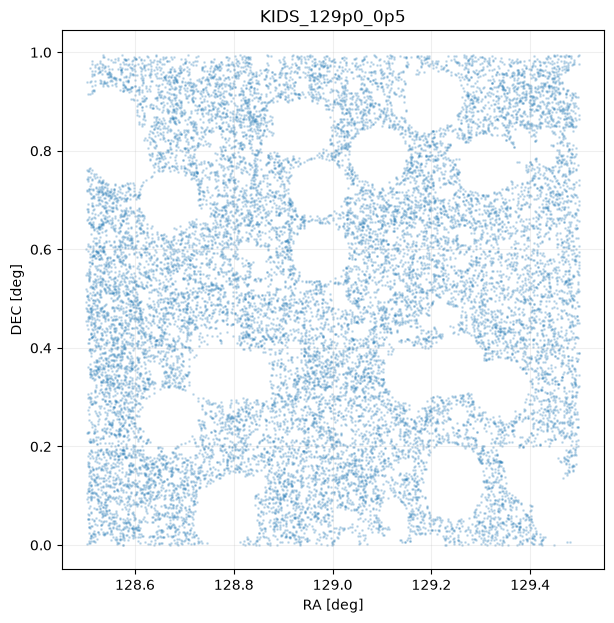

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 7))

plt.scatter(
    ra,
    dec,
    s=1,
    alpha=0.2,
)

plt.xlabel('RA [deg]')
plt.ylabel('DEC [deg]')
plt.title(tile)
plt.grid(alpha=0.2)

plt.show()

In [60]:
import re
import numpy as np

pointing_ra = []
pointing_dec = []
pointing_labels = []

for tile_name in unique_theli:
    tile_name = str(tile_name).strip()
    match = re.fullmatch(r'KIDS_(\d+p\d+)_(m?\d+p\d+)', tile_name)

    if match:
        ra_str, dec_str = match.groups()
        ra_value = float(ra_str.replace('p', '.'))
        dec_value = (
            -float(dec_str[1:].replace('p', '.'))
            if dec_str.startswith('m')
            else float(dec_str.replace('p', '.'))
        )

        pointing_ra.append(ra_value)
        pointing_dec.append(dec_value)
        pointing_labels.append(tile_name)

pointing_ra = np.asarray(pointing_ra)
pointing_dec = np.asarray(pointing_dec)

print('Anzahl erkannter KiDS-Pointings:', len(pointing_ra))
if len(pointing_ra) > 0:
    print('RA-Bereich:', pointing_ra.min(), 'bis', pointing_ra.max())
    print('DEC-Bereich:', pointing_dec.min(), 'bis', pointing_dec.max())
else:
    print('Keine KiDS-Pointings erkannt.')

Anzahl erkannter KiDS-Pointings: 672
RA-Bereich: 129.0 bis 237.0
DEC-Bereich: -3.5 bis 3.5


In [61]:
import re
import numpy as np
import pandas as pd

# Einzigartige KiDS-Tiles aus den bereits deduplizierten THELI_NAME-Werten
kids_tiles = [str(name).strip() for name in unique_theli]
print(f'Anzahl KiDS-Tiles: {len(kids_tiles)}')


def parse_theli_name(name):
    match = re.fullmatch(r'KIDS_(\d+p\d+)_(m?\d+p\d+)', str(name).strip())
    if match is None:
        raise ValueError(f'Unerwartetes THELI_NAME-Format: {name}')

    ra_str, dec_str = match.groups()
    tile_ra = float(ra_str.replace('p', '.'))
    tile_dec = (
        -float(dec_str[1:].replace('p', '.'))
        if dec_str.startswith('m')
        else float(dec_str.replace('p', '.'))
    )
    return tile_ra, tile_dec


tile_data = []
for name in kids_tiles:
    tile_ra, tile_dec = parse_theli_name(name)
    tile_data.append({
        'THELI_NAME': name,
        'RA_center': tile_ra,
        'DEC_center': tile_dec,
    })

kids_tiles_df = pd.DataFrame(tile_data)

print(kids_tiles_df.head())
print()
print(f'Anzahl Tiles: {len(kids_tiles_df)}')

Anzahl KiDS-Tiles: 672
        THELI_NAME  RA_center  DEC_center
0   KIDS_129p0_0p5      129.0         0.5
1   KIDS_129p0_1p5      129.0         1.5
2  KIDS_129p0_m0p5      129.0        -0.5
3  KIDS_129p0_m1p5      129.0        -1.5
4   KIDS_129p4_2p5      129.4         2.5

Anzahl Tiles: 672


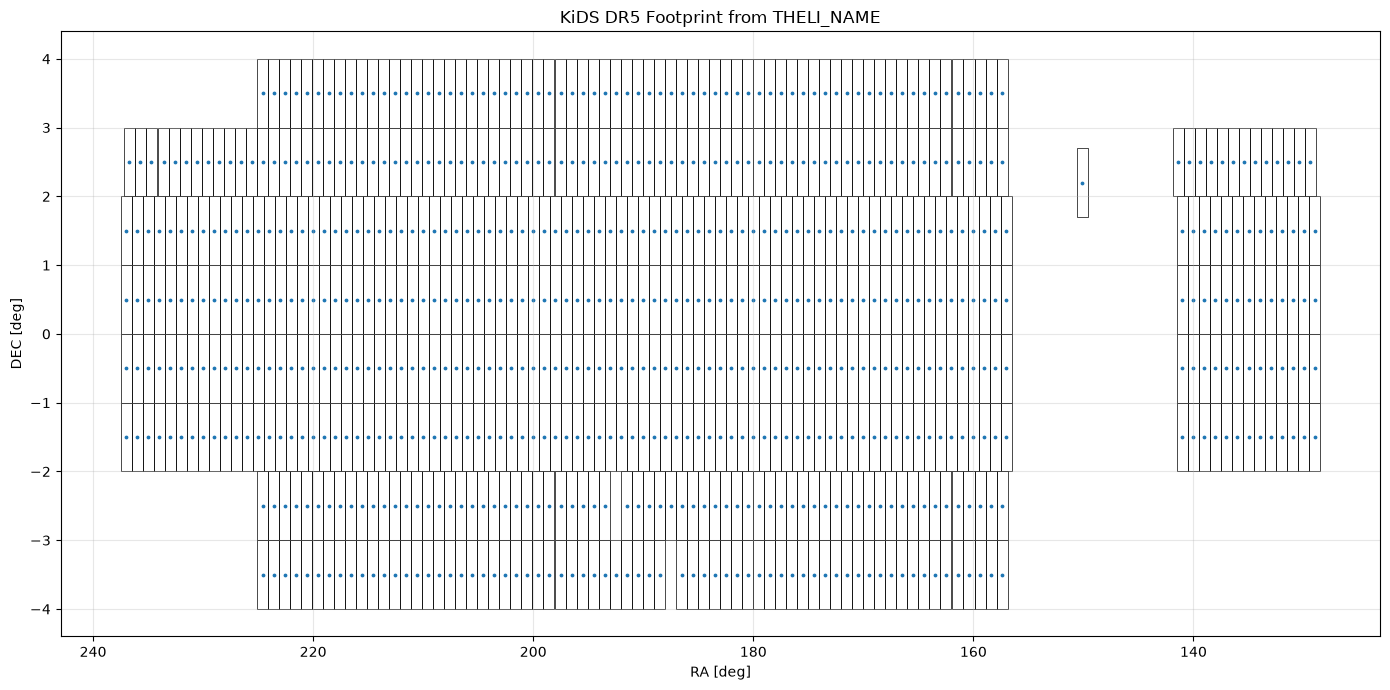

In [62]:
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(14, 7))
tile_size = 1.0

for _, tile_row in kids_tiles_df.iterrows():
    tile_ra_center = tile_row['RA_center']
    tile_dec_center = tile_row['DEC_center']

    rect = Rectangle(
        (tile_ra_center - tile_size / 2, tile_dec_center - tile_size / 2),
        tile_size,
        tile_size,
        fill=False,
        linewidth=0.5,
    )
    ax.add_patch(rect)

ax.scatter(
    kids_tiles_df['RA_center'],
    kids_tiles_df['DEC_center'],
    s=3,
)

ax.set_xlabel('RA [deg]')
ax.set_ylabel('DEC [deg]')
ax.set_title('KiDS DR5 Footprint from THELI_NAME')
ax.invert_xaxis()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

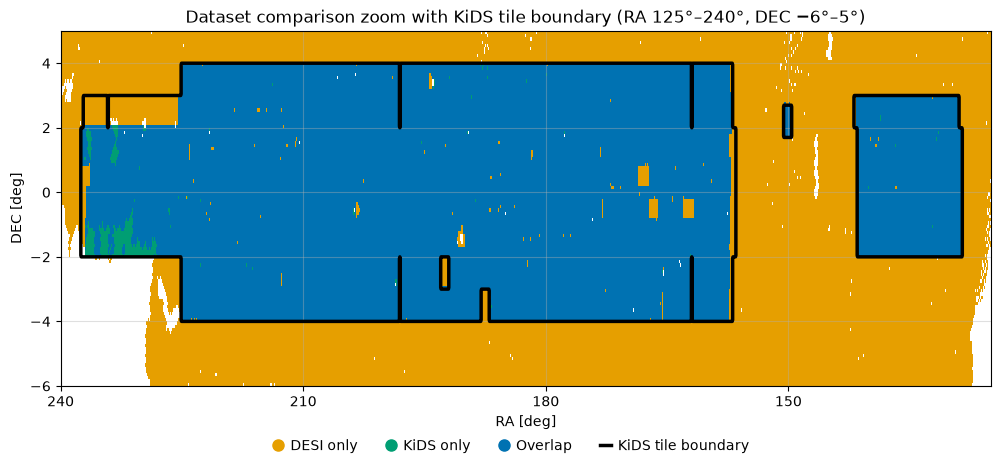

Non-empty bins in zoom: 120,609


In [63]:
from matplotlib.lines import Line2D

ra_longitude_centers = (ra_bins[:-1] + ra_bins[1:]) / 2
ra_centers = (180 - ra_longitude_centers) % 360
dec_centers = (dec_bins[:-1] + dec_bins[1:]) / 2

ra_indices = np.flatnonzero((ra_centers >= 120) & (ra_centers <= 240))
dec_indices = np.flatnonzero((dec_centers >= -10) & (dec_centers <= 10))

zoom_ra_edges = 180 - ra_bins[ra_indices[0]:ra_indices[-1] + 2]
zoom_dec_edges = dec_bins[dec_indices[0]:dec_indices[-1] + 2]
zoom_comparison = comparison[np.ix_(ra_indices, dec_indices)]
zoom_ra_centers = (zoom_ra_edges[:-1] + zoom_ra_edges[1:]) / 2
zoom_dec_centers = (zoom_dec_edges[:-1] + zoom_dec_edges[1:]) / 2

zoom_tile_coverage = np.zeros_like(comparison, dtype=bool)
for tile_row in kids_tiles_df.itertuples(index=False):
    tile_ra_start = np.searchsorted(ra_bins, 180 - (tile_row.RA_center + 0.5))
    tile_ra_end = np.searchsorted(ra_bins, 180 - (tile_row.RA_center - 0.5))
    tile_dec_start = np.searchsorted(dec_bins, tile_row.DEC_center - 0.5)
    tile_dec_end = np.searchsorted(dec_bins, tile_row.DEC_center + 0.5)
    zoom_tile_coverage[tile_ra_start:tile_ra_end, tile_dec_start:tile_dec_end] = True
zoom_tile_coverage = zoom_tile_coverage[np.ix_(ra_indices, dec_indices)]

fig, ax = plt.subplots(figsize=(12, 5))
ax.pcolormesh(
    zoom_ra_edges,
    zoom_dec_edges,
    np.ma.masked_equal(zoom_comparison.T, 0),
    cmap=comparison_cmap,
    norm=comparison_norm,
    shading='auto',
)
ax.contour(
    zoom_ra_centers,
    zoom_dec_centers,
    zoom_tile_coverage.T.astype(float),
    levels=[0.5],
    colors='black',
    linewidths=2.5,
    zorder=5,
)
ax.set_xlim(240, 125)
ax.set_ylim(-6, 5)
ax.set_xticks(np.arange(240, 124, -30))
ax.set_xlabel('RA [deg]')
ax.set_ylabel('DEC [deg]')
ax.grid(True, alpha=0.4)
ax.set_title('Dataset comparison zoom with KiDS tile boundary (RA 125°–240°, DEC −6°–5°)')
zoom_legend_items = legend_items + [
    Line2D([], [], color='black', linewidth=2.5, label='KiDS tile boundary'),
]
fig.legend(
    handles=zoom_legend_items,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.01),
    ncol=4,
    frameon=False,
    handlelength=0.8,
    handletextpad=0.5,
)
fig.subplots_adjust(bottom=0.17)
plt.show()
print(f'Non-empty bins in zoom: {np.count_nonzero(zoom_comparison):,}')

In [64]:
# Tatsächliche Quellen-Ausdehnung pro THELI_NAME

kids_extent = (
    kids_df
    .groupby('THELI_NAME')
    .agg(
        RA_min=('RAJ2000', 'min'),
        RA_max=('RAJ2000', 'max'),
        DEC_min=('DECJ2000', 'min'),
        DEC_max=('DECJ2000', 'max'),
        N_sources=('RAJ2000', 'size'),
    )
    .reset_index()
)

kids_extent['RA_range'] = kids_extent['RA_max'] - kids_extent['RA_min']
kids_extent['DEC_range'] = kids_extent['DEC_max'] - kids_extent['DEC_min']

print(kids_extent.head())
print()
print(f'Anzahl Tiles: {len(kids_extent)}')

          THELI_NAME      RA_min      RA_max   DEC_min   DEC_max  N_sources  \
0  KIDS_129p0_0p5     128.501424  129.499764  0.000037  0.994490      19800   
1  KIDS_129p0_1p5     128.502120  129.499942  0.994500  1.983536      25077   
2  KIDS_129p0_m0p5    128.503576  129.500034 -0.994507 -0.000001      21493   
3  KIDS_129p0_m1p5    128.502111  129.499943 -1.983526 -0.994561      28932   
4  KIDS_129p4_2p5     128.849925  129.860648  1.983525  2.972501      32519   

   RA_range  DEC_range  
0  0.998340   0.994453  
1  0.997822   0.989036  
2  0.996458   0.994506  
3  0.997832   0.988965  
4  1.010723   0.988976  

Anzahl Tiles: 672


In [65]:
# Tile-Zentren aus THELI_NAME

kids_extent = (
    kids_extent
    .drop(columns=['RA_center', 'DEC_center'], errors='ignore')
    .assign(THELI_NAME=lambda frame: frame['THELI_NAME'].astype(str).str.strip())
    .merge(
        kids_tiles_df.assign(
            THELI_NAME=kids_tiles_df['THELI_NAME'].astype(str).str.strip()
        ),
        on='THELI_NAME',
        how='left',
    )
)

# Erwartete Grenzen eines 1° x 1° Tiles
kids_extent['expected_RA_min'] = kids_extent['RA_center'] - 0.5
kids_extent['expected_RA_max'] = kids_extent['RA_center'] + 0.5

kids_extent['expected_DEC_min'] = kids_extent['DEC_center'] - 0.5
kids_extent['expected_DEC_max'] = kids_extent['DEC_center'] + 0.5

# Abstand der tatsächlichen Grenzen von den erwarteten
kids_extent['RA_left_gap'] = (
    kids_extent['RA_min'] - kids_extent['expected_RA_min']
)

kids_extent['RA_right_gap'] = (
    kids_extent['expected_RA_max'] - kids_extent['RA_max']
)

kids_extent['DEC_bottom_gap'] = (
    kids_extent['DEC_min'] - kids_extent['expected_DEC_min']
)

kids_extent['DEC_top_gap'] = (
    kids_extent['expected_DEC_max'] - kids_extent['DEC_max']
)

print(
    kids_extent[
        [
            'THELI_NAME',
            'RA_center',
            'DEC_center',
            'RA_range',
            'DEC_range',
            'N_sources',
        ]
    ].head(20)
)
print()
print('Tiles ohne passendes Zentrum:', kids_extent['RA_center'].isna().sum())

         THELI_NAME  RA_center  DEC_center  RA_range  DEC_range  N_sources
0    KIDS_129p0_0p5      129.0         0.5  0.998340   0.994453      19800
1    KIDS_129p0_1p5      129.0         1.5  0.997822   0.989036      25077
2   KIDS_129p0_m0p5      129.0        -0.5  0.996458   0.994506      21493
3   KIDS_129p0_m1p5      129.0        -1.5  0.997832   0.988965      28932
4    KIDS_129p4_2p5      129.4         2.5  1.010723   0.988976      32519
5    KIDS_130p0_0p5      130.0         0.5  0.999741   0.994448      18535
6    KIDS_130p0_1p5      130.0         1.5  0.999891   0.988903      19393
7   KIDS_130p0_m0p5      130.0        -0.5  0.999671   0.994422      22226
8   KIDS_130p0_m1p5      130.0        -1.5  0.999795   0.988844      26971
9    KIDS_130p4_2p5      130.4         2.5  1.002702   0.988755      18053
10   KIDS_131p0_0p5      131.0         0.5  0.999915   0.994460      24276
11   KIDS_131p0_1p5      131.0         1.5  0.999912   0.988940      24829
12  KIDS_131p0_m0p5      

In [66]:
print("========================================")
print("KiDS Tile-Geometrie")
print("========================================")

print("\nRA-Ausdehnung:")
print(kids_extent["RA_range"].describe())

print("\nDEC-Ausdehnung:")
print(kids_extent["DEC_range"].describe())

print("\nAbstand linke RA-Grenze:")
print(kids_extent["RA_left_gap"].describe())

print("\nAbstand rechte RA-Grenze:")
print(kids_extent["RA_right_gap"].describe())

print("\nAbstand untere DEC-Grenze:")
print(kids_extent["DEC_bottom_gap"].describe())

print("\nAbstand obere DEC-Grenze:")
print(kids_extent["DEC_top_gap"].describe())

KiDS Tile-Geometrie

RA-Ausdehnung:
count    672.000000
mean       0.993147
std        0.064368
min        0.280410
25%        0.999884
50%        0.999981
75%        1.002661
max        1.016163
Name: RA_range, dtype: float64

DEC-Ausdehnung:
count    672.000000
mean       0.975303
std        0.117460
min        0.065211
25%        0.988894
50%        0.988958
75%        0.994298
max        0.994520
Name: DEC_range, dtype: float64

Abstand linke RA-Grenze:
count    672.000000
mean       0.003771
std        0.058396
min       -0.050108
25%        0.000011
50%        0.000067
75%        0.000217
max        0.719298
Name: RA_left_gap, dtype: float64

Abstand rechte RA-Grenze:
count    672.000000
mean       0.003082
std        0.040120
min       -0.050164
25%       -0.000043
50%        0.000004
75%        0.000296
max        0.593259
Name: RA_right_gap, dtype: float64

Abstand untere DEC-Grenze:
count    672.000000
mean       0.003895
std        0.019211
min       -0.027504
25%       -0.0

In [67]:
# Größte Abweichungen von der erwarteten 1° x 1° Geometrie

print("=== RA-Ausreißer ===")
print(
    kids_extent[
        ["THELI_NAME", "RA_center", "DEC_center",
         "RA_min", "RA_max", "RA_range",
         "N_sources"]
    ]
    .sort_values("RA_range")
    .head(15)
)

print("\n=== DEC-Ausreißer ===")
print(
    kids_extent[
        ["THELI_NAME", "RA_center", "DEC_center",
         "DEC_min", "DEC_max", "DEC_range",
         "N_sources"]
    ]
    .sort_values("DEC_range")
    .head(15)
)

=== RA-Ausreißer ===
          THELI_NAME  RA_center  DEC_center      RA_min      RA_max  RA_range  \
69   KIDS_157p0_m1p5      157.0        -1.5  157.219298  157.499708  0.280410   
68   KIDS_157p0_m0p5      157.0        -0.5  157.189701  157.500018  0.310317   
66    KIDS_157p0_0p5      157.0         0.5  157.186993  157.500034  0.313041   
670  KIDS_237p0_m0p5      237.0        -0.5  236.500161  236.906741  0.406580   
671  KIDS_237p0_m1p5      237.0        -1.5  236.500351  236.909442  0.409091   
67    KIDS_157p0_1p5      157.0         1.5  157.030437  157.499989  0.469552   
73   KIDS_157p4_m3p5      157.4        -3.5  157.306868  157.938651  0.631783   
72   KIDS_157p4_m2p5      157.4        -2.5  157.218027  157.938729  0.720702   
64    KIDS_141p4_2p5      141.4         2.5  140.891407  141.659647  0.768240   
668   KIDS_237p0_0p5      237.0         0.5  236.500035  237.303963  0.803928   
669   KIDS_237p0_1p5      237.0         1.5  236.500013  237.304819  0.804806   
71    K

In [68]:
print(
    kids_extent[
        [
            "THELI_NAME",
            "RA_center", "DEC_center",
            "RA_range", "DEC_range",
            "N_sources",
        ]
    ]
    .sort_values("N_sources")
    .head(20)
)

          THELI_NAME  RA_center  DEC_center  RA_range  DEC_range  N_sources
647   KIDS_232p6_2p5      232.6         2.5  0.993523   0.065820       1145
652   KIDS_233p6_2p5      233.6         2.5  0.987754   0.065418       1351
627   KIDS_228p6_2p5      228.6         2.5  1.002255   0.065211       1387
657   KIDS_234p7_2p5      234.7         2.5  0.996224   0.065280       1431
617   KIDS_226p6_2p5      226.6         2.5  1.000790   0.065814       1535
632   KIDS_229p6_2p5      229.6         2.5  1.001223   0.065777       1716
662   KIDS_235p7_2p5      235.7         2.5  1.001858   0.066130       2076
637   KIDS_230p6_2p5      230.6         2.5  1.002686   0.065643       2185
642   KIDS_231p6_2p5      231.6         2.5  1.002172   0.065445       2538
667   KIDS_236p7_2p5      236.7         2.5  1.001914   0.065887       2594
622   KIDS_227p6_2p5      227.6         2.5  0.999096   0.065836       2820
668   KIDS_237p0_0p5      237.0         0.5  0.803928   0.994266       5442
69   KIDS_15

In [69]:
# Tiles mit ungewöhnlich kleiner Ausdehnung
small_tiles = kids_extent[
    (kids_extent["RA_range"] < 0.9) |
    (kids_extent["DEC_range"] < 0.9)
]

print(f"Anzahl auffälliger Tiles: {len(small_tiles)}")

print(
    small_tiles[
        ["THELI_NAME",
         "RA_center", "DEC_center",
         "RA_range", "DEC_range",
         "N_sources"]
    ].sort_values("RA_range")
)

Anzahl auffälliger Tiles: 22
          THELI_NAME  RA_center  DEC_center  RA_range  DEC_range  N_sources
69   KIDS_157p0_m1p5      157.0        -1.5  0.280410   0.988451       5510
68   KIDS_157p0_m0p5      157.0        -0.5  0.310317   0.994249       8131
66    KIDS_157p0_0p5      157.0         0.5  0.313041   0.994181       9387
670  KIDS_237p0_m0p5      237.0        -0.5  0.406580   0.994208       7123
671  KIDS_237p0_m1p5      237.0        -1.5  0.409091   0.987497       9164
67    KIDS_157p0_1p5      157.0         1.5  0.469552   0.988629       6200
73   KIDS_157p4_m3p5      157.4        -3.5  0.631783   0.988831      19512
72   KIDS_157p4_m2p5      157.4        -2.5  0.720702   0.988892      21576
64    KIDS_141p4_2p5      141.4         2.5  0.768240   0.988759      21249
668   KIDS_237p0_0p5      237.0         0.5  0.803928   0.994266       5442
669   KIDS_237p0_1p5      237.0         1.5  0.804806   0.988992      25241
652   KIDS_233p6_2p5      233.6         2.5  0.987754   0.0

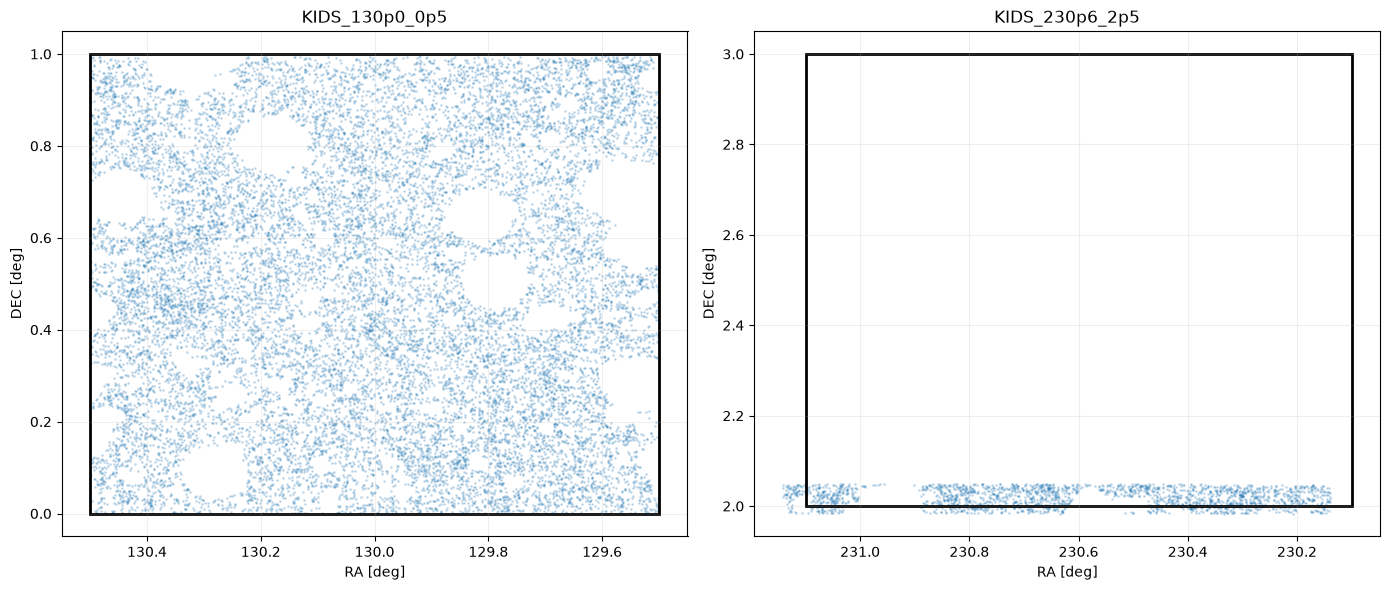

In [70]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# THELI_NAME kann mit Leerzeichen aufgefuellt sein.
kids_theli_names = kids_df["THELI_NAME"].astype(str).str.strip()

tiles_to_check = [
    "KIDS_130p0_0p5",   # normales Tile
    "KIDS_230p6_2p5",   # auffaelliges Rand-Tile
]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, tile_name in zip(axes, tiles_to_check):
    data = kids_df.loc[kids_theli_names == tile_name]

    tile_match = kids_tiles_df.loc[
        kids_tiles_df["THELI_NAME"].astype(str).str.strip() == tile_name
    ]
    if tile_match.empty:
        raise ValueError(f"Tile-Zentrum nicht gefunden: {tile_name}")
    if data.empty:
        raise ValueError(f"Keine KiDS-Quellen fuer Tile gefunden: {tile_name}")

    tile = tile_match.iloc[0]
    ra_center = tile["RA_center"]
    dec_center = tile["DEC_center"]

    # Tatsächliche KiDS-Quellen
    ax.scatter(
        data["RAJ2000"],
        data["DECJ2000"],
        s=1,
        alpha=0.2,
    )

    # Nominales 1° x 1° Tile
    rect = Rectangle(
        (ra_center - 0.5, dec_center - 0.5),
        1.0,
        1.0,
        fill=False,
        linewidth=2,
    )
    ax.add_patch(rect)

    ax.set_title(tile_name)
    ax.set_xlabel("RA [deg]")
    ax.set_ylabel("DEC [deg]")
    ax.invert_xaxis()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


KIDS_130p0_0p5
 0.100° :    2 /  110 empty bins (1.82%)


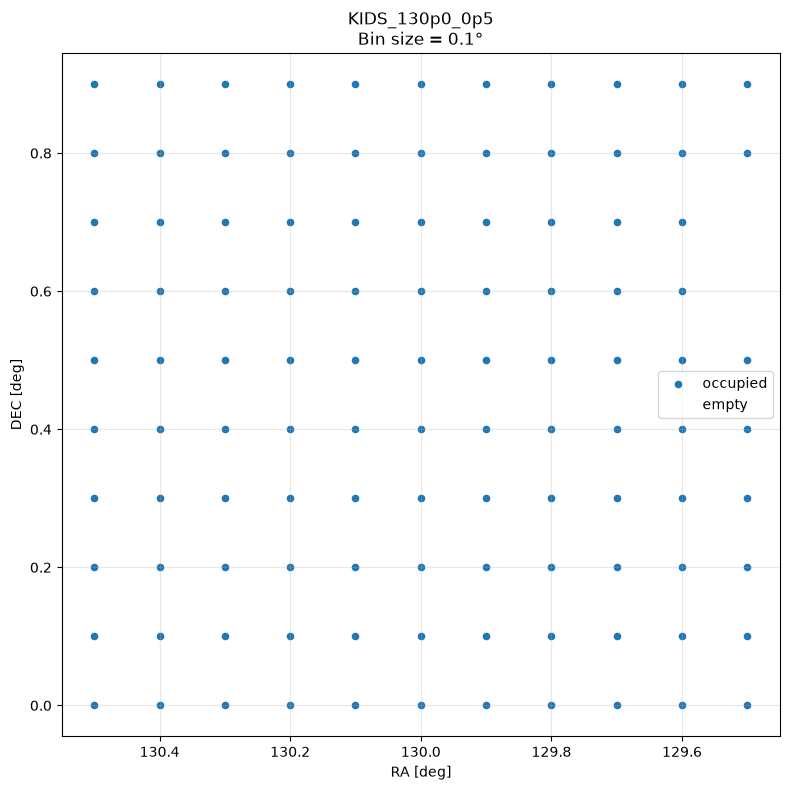

 0.050° :   79 /  462 empty bins (17.10%)


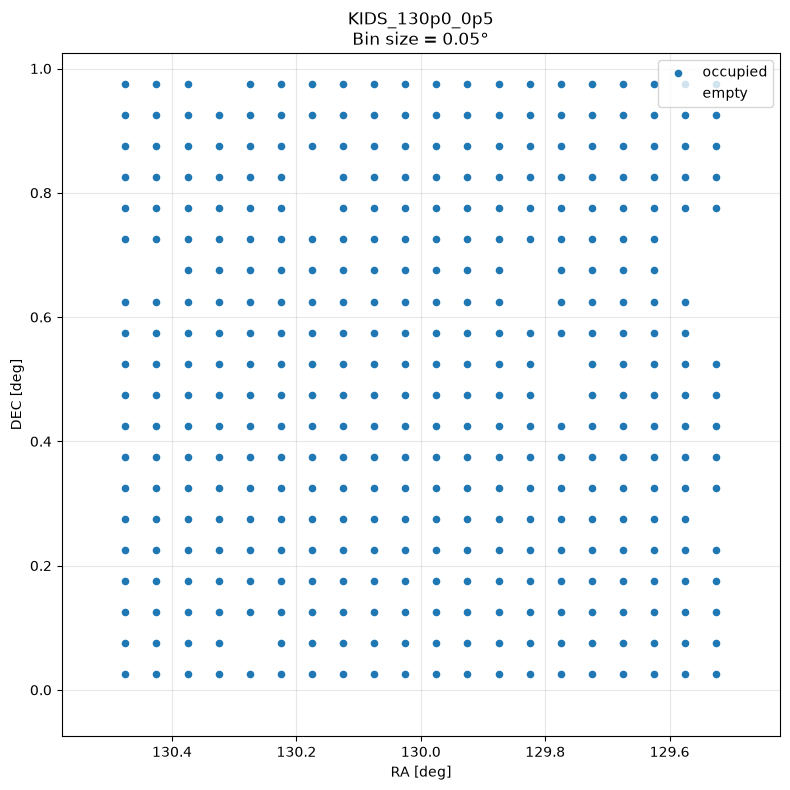

 0.025° :  433 / 1892 empty bins (22.89%)


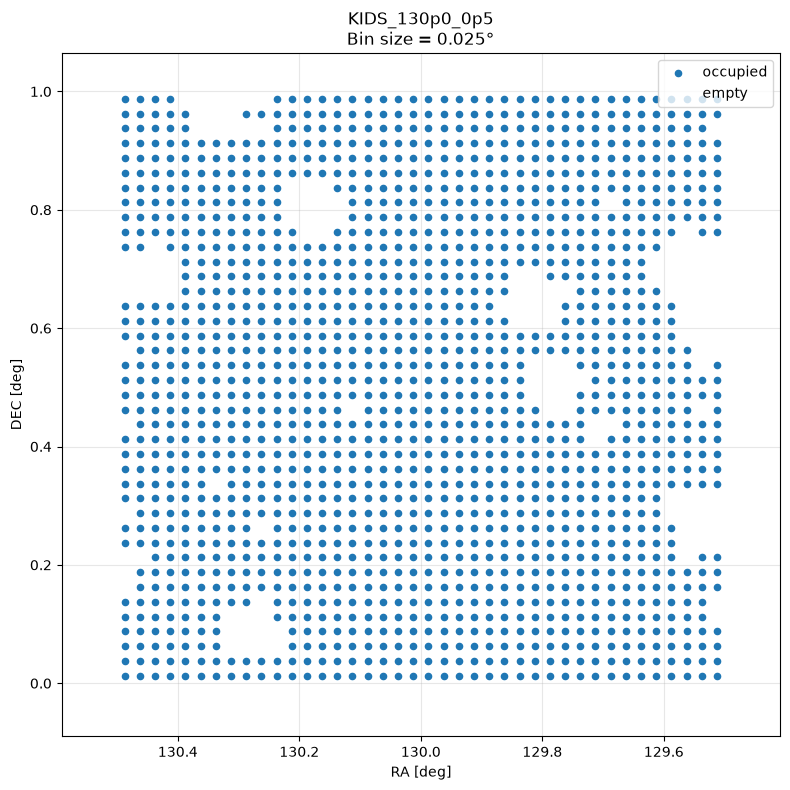


KIDS_230p6_2p5
 0.100° :   99 /  110 empty bins (90.00%)


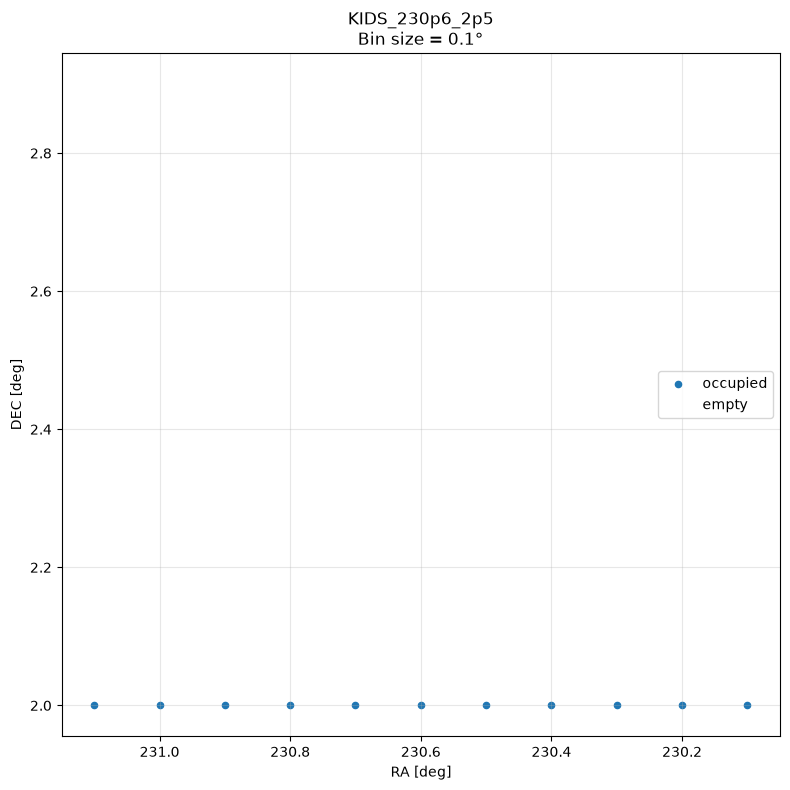

 0.050° :  423 /  462 empty bins (91.56%)


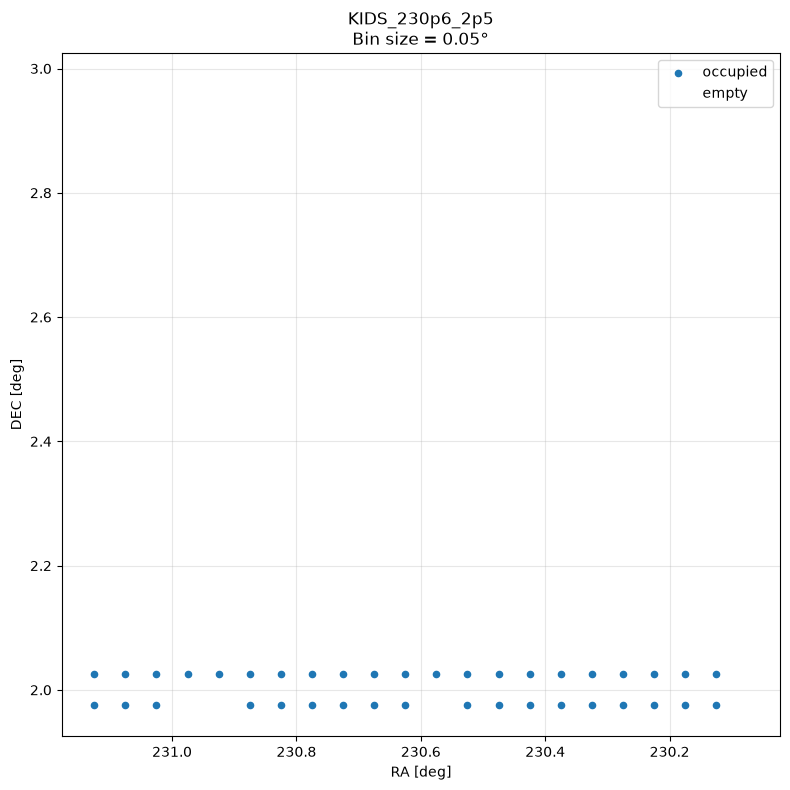

 0.025° : 1784 / 1892 empty bins (94.29%)


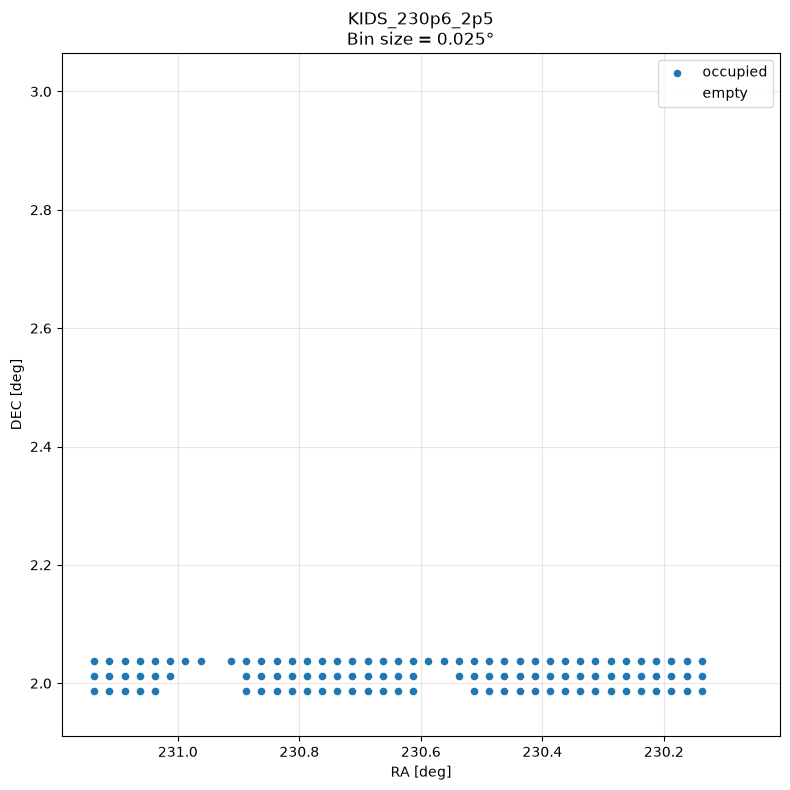

In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# KiDS-Tile in feste, zentrierte Bins aufteilen
def bin_kids_tile_fixed(kids, tile_name, bin_size):
    tile_names = kids_tiles_df["THELI_NAME"].astype(str).str.strip()
    tile = kids_tiles_df.loc[tile_names == tile_name].iloc[0]

    ra_center = tile["RA_center"]
    dec_center = tile["DEC_center"]

    ra_min = ra_center - 0.55
    ra_max = ra_center + 0.55
    dec_min = dec_center - 0.55
    dec_max = dec_center + 0.55

    ra_bins = np.arange(ra_min, ra_max, bin_size)
    dec_bins = np.arange(dec_min, dec_max, bin_size)

    mask = kids["THELI_NAME"].astype(str).str.strip() == tile_name
    ra = np.asarray(kids.loc[mask, "RAJ2000"])
    dec = np.asarray(kids.loc[mask, "DECJ2000"])

    counts, _, _ = np.histogram2d(
        ra,
        dec,
        bins=[ra_bins, dec_bins],
    )

    ra_centers = (ra_bins[:-1] + ra_bins[1:]) / 2
    dec_centers = (dec_bins[:-1] + dec_bins[1:]) / 2
    RA_grid, DEC_grid = np.meshgrid(
        ra_centers,
        dec_centers,
        indexing="ij",
    )

    return pd.DataFrame({
        "RA": RA_grid.flatten(),
        "DEC": DEC_grid.flatten(),
        "N_sources": counts.flatten(),
    })


def plot_binned_tile(tile_bins, tile_name, bin_size):
    fig, ax = plt.subplots(figsize=(8, 8))

    occupied = tile_bins["N_sources"] > 0
    empty = tile_bins["N_sources"] == 0

    ax.scatter(
        tile_bins.loc[occupied, "RA"],
        tile_bins.loc[occupied, "DEC"],
        s=20,
        label="occupied",
    )
    ax.scatter(
        tile_bins.loc[empty, "RA"],
        tile_bins.loc[empty, "DEC"],
        s=20,
        marker="s",
        facecolors="none",
        label="empty",
    )

    ax.set_xlabel("RA [deg]")
    ax.set_ylabel("DEC [deg]")
    ax.set_title(f"{tile_name}\nBin size = {bin_size}°")
    ax.invert_xaxis()
    ax.grid(alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()


# Beide Tiles mit mehreren Bin-Groessen vergleichen
tile_normal = "KIDS_130p0_0p5"
tile_problem = "KIDS_230p6_2p5"
bin_sizes = [0.10, 0.05, 0.025]

for tile_name in [tile_normal, tile_problem]:
    print("\n======================================")
    print(tile_name)
    print("======================================")

    for bin_size in bin_sizes:
        tile_bin_grid_df = bin_kids_tile_fixed(kids_df, tile_name, bin_size)

        n_total = len(tile_bin_grid_df)
        n_empty = (tile_bin_grid_df["N_sources"] == 0).sum()

        print(
            f"{bin_size:6.3f}° : "
            f"{n_empty:4d} / {n_total:4d} empty bins "
            f"({100 * n_empty / n_total:.2f}%)"
        )

        plot_binned_tile(tile_bin_grid_df, tile_name, bin_size)


KIDS_130p0_0p5: 1 Leerregionen (mindestens 10 leere Bins horizontal oder vertikal)
 region_id  N_bins  area_deg2
         1     292     0.1825


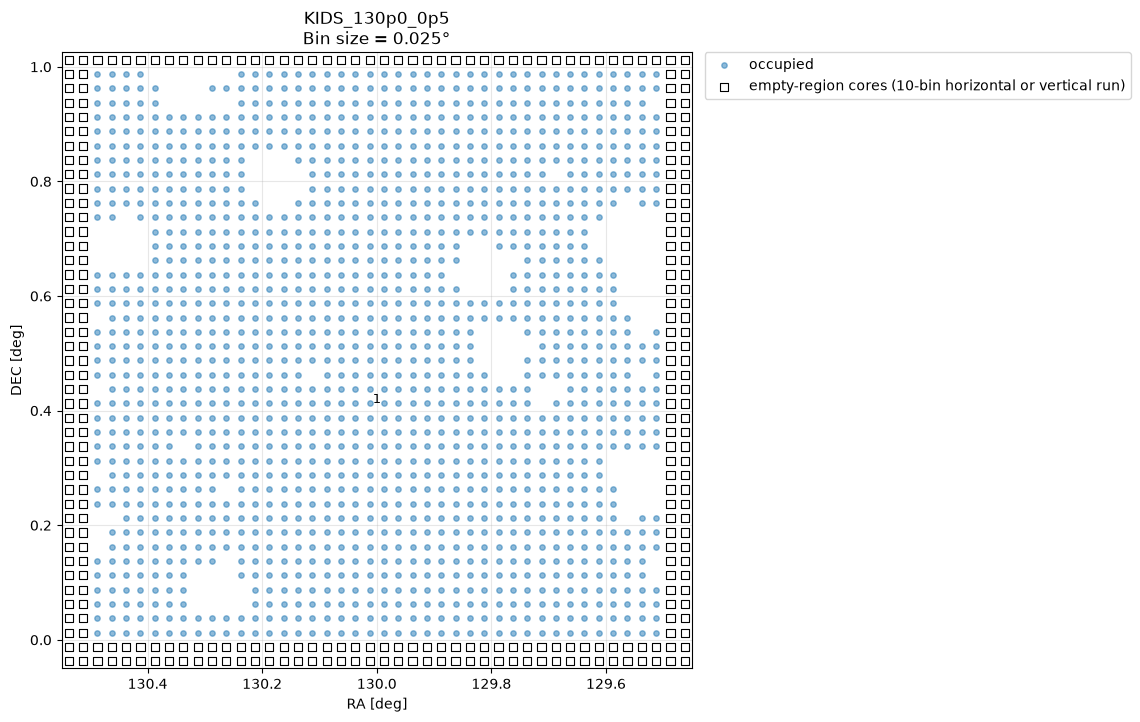


KIDS_230p6_2p5: 1 Leerregionen (mindestens 10 leere Bins horizontal oder vertikal)
 region_id  N_bins  area_deg2
         1    1772     1.1075


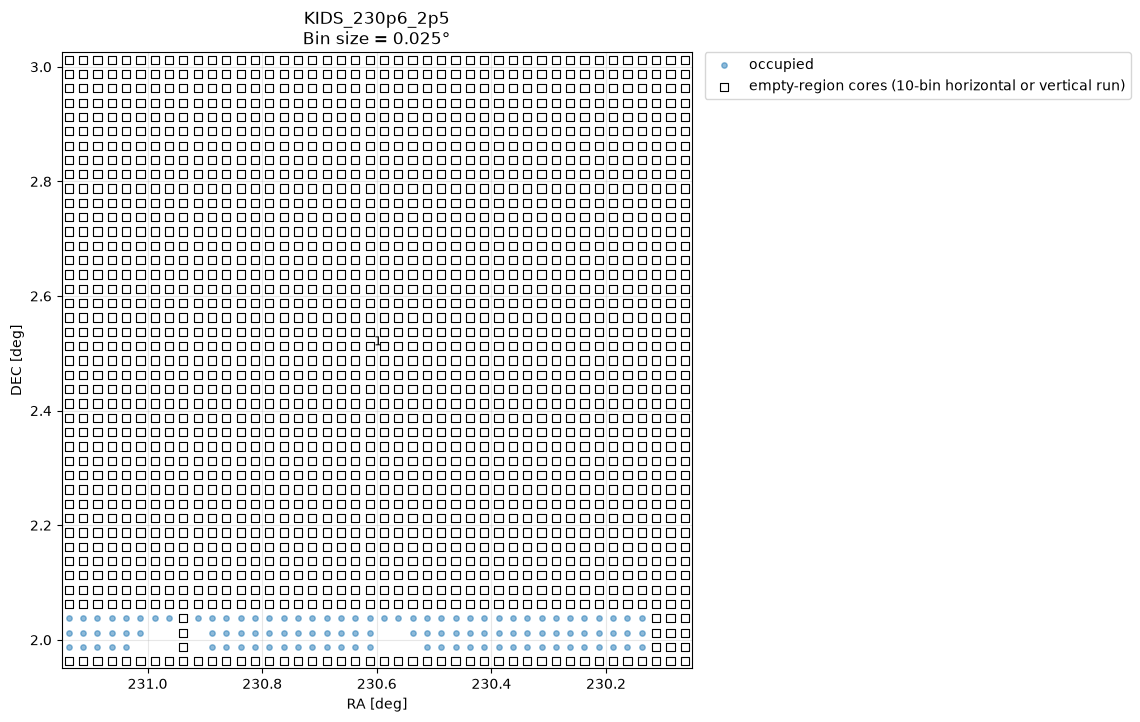

In [72]:
from scipy.ndimage import binary_opening, label as label_regions


def _bins_to_grid(bins):
    required_columns = {"RA", "DEC", "N_sources"}
    missing_columns = required_columns.difference(bins.columns)
    if missing_columns:
        raise ValueError(f"Fehlende Spalten: {sorted(missing_columns)}")
    if bins.empty:
        raise ValueError("Das Bin-DataFrame ist leer.")
    if bins[["RA", "DEC", "N_sources"]].isna().to_numpy().any():
        raise ValueError("RA, DEC und N_sources dürfen keine fehlenden Werte enthalten.")
    if bins.duplicated(["RA", "DEC"]).any():
        raise ValueError("Jede RA/DEC-Bin-Kombination muss eindeutig sein.")

    grid = bins.pivot(index="RA", columns="DEC", values="N_sources")
    if grid.isna().to_numpy().any():
        raise ValueError("Die Bins bilden kein vollständiges rechteckiges Raster.")

    return grid.sort_index(axis=0).sort_index(axis=1)


def retain_empty_regions_with_axis_run(empty, min_run_length):
    if min_run_length < 1:
        raise ValueError("min_run_length muss mindestens 1 sein.")

    horizontal = binary_opening(
        empty,
        structure=np.ones((1, min_run_length), dtype=bool),
    )
    vertical = binary_opening(
        empty,
        structure=np.ones((min_run_length, 1), dtype=bool),
    )
    return horizontal | vertical


def find_empty_regions(
    bins,
    bin_size,
    connectivity=8,
    min_run_length=10,
):
    if bin_size <= 0:
        raise ValueError("bin_size muss groesser als 0 sein.")
    if connectivity not in (4, 8):
        raise ValueError("connectivity muss 4 oder 8 sein.")
    if min_run_length < 1:
        raise ValueError("min_run_length muss mindestens 1 sein.")

    grid = _bins_to_grid(bins)
    empty = grid.to_numpy() == 0
    qualifying_empty = retain_empty_regions_with_axis_run(empty, min_run_length)

    structure = (
        np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]], dtype=np.uint8)
        if connectivity == 4
        else np.ones((3, 3), dtype=np.uint8)
    )
    region_labels, n_regions = label_regions(qualifying_empty, structure=structure)

    all_region_sizes = np.bincount(region_labels.ravel(), minlength=n_regions + 1)
    region_ids = np.flatnonzero(all_region_sizes[1:]) + 1
    region_sizes = all_region_sizes[region_ids]
    regions = pd.DataFrame({
        "region_id": region_ids,
        "N_bins": region_sizes,
        "area_deg2": region_sizes * bin_size**2,
    })
    regions = regions.sort_values(
        "N_bins", ascending=False, ignore_index=True
    )

    return region_labels, regions


def plot_empty_regions(
    bins,
    region_labels,
    regions,
    tile_name,
    bin_size,
    min_region_bins=1,
):
    grid = _bins_to_grid(bins)
    ra_grid, dec_grid = np.meshgrid(
        grid.index.to_numpy(),
        grid.columns.to_numpy(),
        indexing="ij",
    )
    source_counts = grid.to_numpy()

    fig, ax = plt.subplots(figsize=(10, 8))

    occupied = source_counts > 0
    ax.scatter(
        ra_grid[occupied],
        dec_grid[occupied],
        s=15,
        alpha=0.5,
        label="occupied",
    )

    drawable_regions = regions.loc[regions["N_bins"] >= min_region_bins]
    empty_regions_mask = np.isin(
        region_labels,
        drawable_regions["region_id"].to_numpy(),
    )
    if empty_regions_mask.any():
        ax.scatter(
            ra_grid[empty_regions_mask],
            dec_grid[empty_regions_mask],
            s=35,
            marker="s",
            facecolors="none",
            edgecolors="black",
            linewidths=0.8,
            label="empty-region cores (10-bin horizontal or vertical run)",
        )

    for region_id in drawable_regions["region_id"]:
        region_mask = region_labels == region_id
        ax.text(
            ra_grid[region_mask].mean(),
            dec_grid[region_mask].mean(),
            str(region_id),
            ha="center",
            va="center",
            fontsize=9,
        )

    ax.set_xlabel("RA [deg]")
    ax.set_ylabel("DEC [deg]")
    ax.set_title(f"{tile_name}\nBin size = {bin_size}°")
    ax.set_xlim(
        ra_grid.max() + bin_size / 2,
        ra_grid.min() - bin_size / 2,
    )
    ax.set_ylim(
        dec_grid.min() - bin_size / 2,
        dec_grid.max() + bin_size / 2,
    )
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)

    fig.subplots_adjust(right=0.76)
    plt.show()


empty_region_bin_size = 0.025
min_empty_run_length = 10
for empty_region_tile in (tile_normal, tile_problem):
    tile_bins = bin_kids_tile_fixed(
        kids_df,
        empty_region_tile,
        empty_region_bin_size,
    )
    region_labels, empty_regions = find_empty_regions(
        tile_bins,
        empty_region_bin_size,
        connectivity=8,
        min_run_length=min_empty_run_length,
    )

    print(
        f"\n{empty_region_tile}: {len(empty_regions)} Leerregionen "
        f"(mindestens {min_empty_run_length} leere Bins horizontal oder vertikal)"
    )
    print(empty_regions.head(10).to_string(index=False))
    plot_empty_regions(
        tile_bins,
        region_labels,
        empty_regions,
        empty_region_tile,
        empty_region_bin_size,
        min_region_bins=2,
    )

In [73]:
from scipy.ndimage import binary_opening, label as label_regions

full_kids_data = kids_df
full_ra_column = full_kids_data["RAJ2000"].to_numpy()
full_dec_column = full_kids_data["DECJ2000"].to_numpy()
full_bin_size = 0.025
full_min_run_length = 10
chunk_size = 1_000_000
plot_dec_min = -6.0
plot_dec_max = 5.0

# Find finite DEC limits without copying the full catalog into memory.
full_dec_min = np.inf
full_dec_max = -np.inf
n_valid_coordinates = 0
for start in range(0, len(full_kids_data), chunk_size):
    stop = min(start + chunk_size, len(full_kids_data))
    ra_chunk = np.asarray(full_ra_column[start:stop], dtype=np.float64)
    dec_chunk = np.asarray(full_dec_column[start:stop], dtype=np.float64)
    valid = np.isfinite(ra_chunk) & np.isfinite(dec_chunk)
    if valid.any():
        valid_dec = dec_chunk[valid]
        full_dec_min = min(full_dec_min, valid_dec.min())
        full_dec_max = max(full_dec_max, valid_dec.max())
        n_valid_coordinates += int(valid.sum())

if n_valid_coordinates == 0:
    raise ValueError("Im gefilterten KiDS-Datensatz wurden keine gueltigen Koordinaten gefunden.")

full_dec_min = min(np.floor(full_dec_min / full_bin_size) * full_bin_size, plot_dec_min)
full_dec_max = max(np.ceil(full_dec_max / full_bin_size) * full_bin_size, plot_dec_max)
n_ra_bins = int(round(360 / full_bin_size))
n_dec_bins = int(round((full_dec_max - full_dec_min) / full_bin_size))
ra_edges = np.linspace(0.0, 360.0, n_ra_bins + 1)

print(f"KiDS-Katalogzeilen nach DEC-Filter: {len(full_kids_data):,}")
print(f"Aktiver Filter: DECJ2000 >= -15°")
print(f"Gueltige RA/DEC-Koordinaten: {n_valid_coordinates:,}")
print(f"Raster-DEC-Bereich inklusive leerem Rand: {full_dec_min:.3f}° bis {full_dec_max:.3f}°")
print(f"Raster: {n_ra_bins:,} x {n_dec_bins:,} Bins bei {full_bin_size}°")
print(f"Mindestlauflaenge: {full_min_run_length} Bins ({full_min_run_length * full_bin_size:.3f}°) horizontal oder vertikal")
print(f"Geschaetzter Spitzenbedarf fuer Rasterarrays: {n_ra_bins * n_dec_bins * 20 / 1024**3:.2f} GiB")

full_counts = np.zeros((n_ra_bins, n_dec_bins), dtype=np.uint32)
full_counts_flat = full_counts.ravel()
for start in range(0, len(full_kids_data), chunk_size):
    stop = min(start + chunk_size, len(full_kids_data))
    ra_chunk = np.asarray(full_ra_column[start:stop], dtype=np.float64)
    dec_chunk = np.asarray(full_dec_column[start:stop], dtype=np.float64)
    valid = np.isfinite(ra_chunk) & np.isfinite(dec_chunk)
    if not valid.any():
        continue

    ra_valid = np.mod(ra_chunk[valid], 360.0)
    dec_valid = dec_chunk[valid]
    ra_indices = np.floor(ra_valid / full_bin_size).astype(np.int32)
    dec_indices = np.floor((dec_valid - full_dec_min) / full_bin_size).astype(np.int32)
    np.minimum(ra_indices, n_ra_bins - 1, out=ra_indices)
    np.minimum(dec_indices, n_dec_bins - 1, out=dec_indices)
    flat_indices = ra_indices.astype(np.int64) * n_dec_bins + dec_indices
    np.add.at(full_counts_flat, flat_indices, np.uint32(1))

del full_counts_flat
full_empty = full_counts == 0
del full_counts

# Wrap RA while opening so empty runs crossing RA=0° remain connected.
ra_halo = full_min_run_length - 1
periodic_empty = np.pad(
    full_empty,
    ((ra_halo, ra_halo), (0, 0)),
    mode="wrap",
)
qualifying_empty_padded = retain_empty_regions_with_axis_run(
    periodic_empty,
    full_min_run_length,
)
qualifying_empty = qualifying_empty_padded[ra_halo:-ra_halo, :].copy()
del full_empty, periodic_empty, qualifying_empty_padded

# Label the qualifying raster and merge components crossing the RA seam.
full_structure = np.ones((3, 3), dtype=np.uint8)
full_region_labels, n_full_regions = label_regions(
    qualifying_empty,
    structure=full_structure,
)
del qualifying_empty

parents = np.arange(n_full_regions + 1, dtype=np.int32)

def find_region_root(region_id):
    while parents[region_id] != region_id:
        parents[region_id] = parents[parents[region_id]]
        region_id = parents[region_id]
    return region_id


edge_pairs = []
for dec_shift in (-1, 0, 1):
    if dec_shift < 0:
        first_edge = full_region_labels[0, 1:]
        last_edge = full_region_labels[-1, :-1]
    elif dec_shift > 0:
        first_edge = full_region_labels[0, :-1]
        last_edge = full_region_labels[-1, 1:]
    else:
        first_edge = full_region_labels[0, :]
        last_edge = full_region_labels[-1, :]

    connected = (first_edge > 0) & (last_edge > 0)
    if connected.any():
        edge_pairs.append(np.column_stack((first_edge[connected], last_edge[connected])))

if edge_pairs:
    for left_id, right_id in np.unique(np.concatenate(edge_pairs), axis=0):
        left_root = find_region_root(int(left_id))
        right_root = find_region_root(int(right_id))
        if left_root != right_root:
            parents[right_root] = left_root

root_map = np.arange(n_full_regions + 1, dtype=np.int32)
for region_id in range(1, n_full_regions + 1):
    root_map[region_id] = find_region_root(region_id)
full_region_labels = root_map[full_region_labels]

full_region_sizes = np.bincount(full_region_labels.ravel(), minlength=n_full_regions + 1)
full_region_ids = np.flatnonzero(full_region_sizes[1:]) + 1
full_region_sizes = full_region_sizes[full_region_ids]
full_empty_regions = pd.DataFrame({
    "region_id": full_region_ids,
    "N_bins_10run_core": full_region_sizes,
    "area_deg2_10run_core": full_region_sizes * full_bin_size**2,
})
full_empty_regions = full_empty_regions.sort_values(
    "area_deg2_10run_core",
    ascending=False,
    ignore_index=True,
)

print(f"\nEmpty-Regions mit mindestens {full_min_run_length} leeren Bins horizontal oder vertikal: {len(full_empty_regions):,}")
print(f"Gesamtflaeche der Regionskerne: {full_empty_regions['area_deg2_10run_core'].sum():,.6f} deg²")
if full_empty_regions.empty:
    print("Keine Empty-Regions gefunden.")
else:
    print(full_empty_regions.to_string(
        index=False,
        formatters={"area_deg2_10run_core": lambda area: f"{area:.6f}"},
    ))

KiDS-Katalogzeilen nach DEC-Filter: 20,471,163
Aktiver Filter: DECJ2000 >= -15°
Gueltige RA/DEC-Koordinaten: 20,471,163
Raster-DEC-Bereich inklusive leerem Rand: -6.000° bis 5.000°
Raster: 14,400 x 440 Bins bei 0.025°
Mindestlauflaenge: 10 Bins (0.250°) horizontal oder vertikal
Geschaetzter Spitzenbedarf fuer Rasterarrays: 0.12 GiB

Empty-Regions mit mindestens 10 leeren Bins horizontal oder vertikal: 206
Gesamtflaeche der Regionskerne: 3,320.128125 deg²
 region_id  N_bins_10run_core area_deg2_10run_core
         1            5297069          3310.668125
        45               3387             2.116875
        32               1686             1.053750
       138               1505             0.940625
       128                969             0.605625
       140                574             0.358750
       156                394             0.246250
        70                322             0.201250
        73                199             0.124375
        62                185  

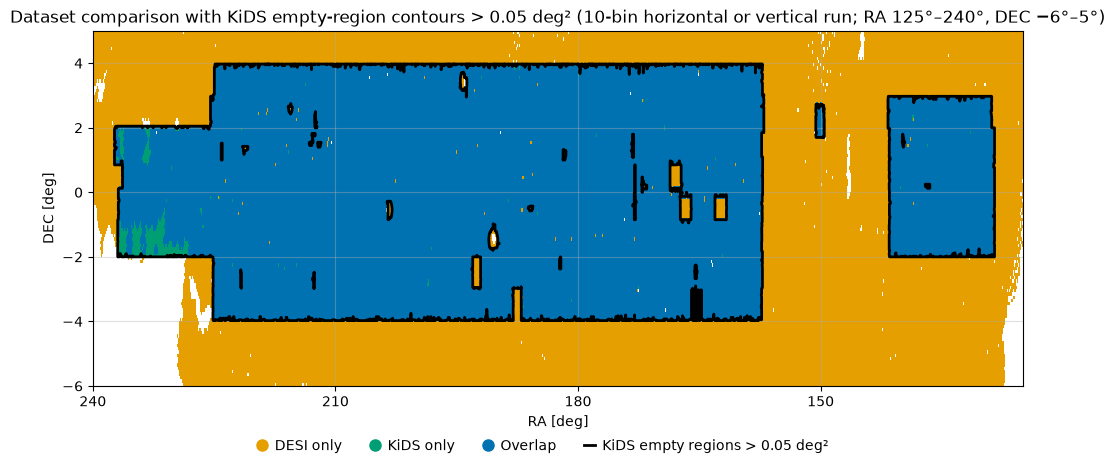

KiDS-Empty-Regions konturiert (> 0.05 deg²): 24
Non-empty bins im unveränderten Vergleichsplot: 120,609


In [74]:
from matplotlib.lines import Line2D

region_area_threshold = 0.05
selected_empty_region_ids = full_empty_regions.loc[
    full_empty_regions["area_deg2_10run_core"] > region_area_threshold,
    "region_id",
].to_numpy()
selected_empty_region_mask = np.isin(
    full_region_labels,
    selected_empty_region_ids,
)

comparison_ra_centers = (ra_bins[:-1] + ra_bins[1:]) / 2
comparison_ra_as_degrees = (180 - comparison_ra_centers) % 360
comparison_dec_centers = (dec_bins[:-1] + dec_bins[1:]) / 2

plot_ra_centers = (np.arange(n_ra_bins) + 0.5) * full_bin_size
plot_dec_centers = full_dec_min + (np.arange(n_dec_bins) + 0.5) * full_bin_size
plot25_ra_indices = np.flatnonzero(
    (comparison_ra_as_degrees >= 120) & (comparison_ra_as_degrees <= 240)
)
plot25_dec_indices = np.flatnonzero(
    (comparison_dec_centers >= -10) & (comparison_dec_centers <= 10)
)
plot25_ra_edges = 180 - ra_bins[plot25_ra_indices[0]:plot25_ra_indices[-1] + 2]
plot25_dec_edges = dec_bins[plot25_dec_indices[0]:plot25_dec_indices[-1] + 2]
plot25_zoom_comparison = comparison[np.ix_(plot25_ra_indices, plot25_dec_indices)]
plot25_zoom_ra_centers = (plot25_ra_edges[:-1] + plot25_ra_edges[1:]) / 2
plot25_zoom_dec_centers = (plot25_dec_edges[:-1] + plot25_dec_edges[1:]) / 2

plot25_contour_ra_indices = np.flatnonzero(
    (plot_ra_centers >= 125) & (plot_ra_centers <= 240)
)
plot25_contour_dec_indices = np.flatnonzero(
    (plot_dec_centers >= -6) & (plot_dec_centers <= 5)
)
plot25_empty_region_contour = selected_empty_region_mask[
    np.ix_(plot25_contour_ra_indices, plot25_contour_dec_indices)
]

fig, ax = plt.subplots(figsize=(12, 5))
ax.pcolormesh(
    plot25_ra_edges,
    plot25_dec_edges,
    np.ma.masked_equal(plot25_zoom_comparison.T, 0),
    cmap=comparison_cmap,
    norm=comparison_norm,
    shading="auto",
)
if plot25_empty_region_contour.any() and not plot25_empty_region_contour.all():
    ax.contour(
        plot_ra_centers[plot25_contour_ra_indices],
        plot_dec_centers[plot25_contour_dec_indices],
        plot25_empty_region_contour.T.astype(float),
        levels=[0.5],
        colors="black",
        linewidths=2.0,
        zorder=6,
    )

ax.set_xlim(240, 125)
ax.set_ylim(-6, 5)
ax.set_xticks(np.arange(240, 124, -30))
ax.set_xlabel("RA [deg]")
ax.set_ylabel("DEC [deg]")
ax.grid(True, alpha=0.4)
ax.set_title(
    f"Dataset comparison with KiDS empty-region contours > {region_area_threshold} deg² "
    "(10-bin horizontal or vertical run; RA 125°–240°, DEC −6°–5°)"
)
plot25_legend_items = legend_items + [
    Line2D(
        [],
        [],
        color="black",
        linewidth=2.0,
        label=f"KiDS empty regions > {region_area_threshold} deg²",
    ),
]
fig.legend(
    handles=plot25_legend_items,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=4,
    frameon=False,
    handlelength=0.8,
    handletextpad=0.5,
)
fig.subplots_adjust(bottom=0.17)
plt.show()

print(f"KiDS-Empty-Regions konturiert (> {region_area_threshold} deg²): {len(selected_empty_region_ids)}")
print(f"Non-empty bins im unveränderten Vergleichsplot: {np.count_nonzero(plot25_zoom_comparison):,}")

In [75]:
desi_region_bin_size = 0.025
desi_min_run_length = 10
desi_region_area_threshold = 0.05
desi_plot_dec_min = -6.0
desi_plot_dec_max = 5.0
desi_n_ra_bins = int(round(360 / desi_region_bin_size))
desi_n_dec_bins = int(round((desi_plot_dec_max - desi_plot_dec_min) / desi_region_bin_size))
desi_counts = np.zeros((desi_n_ra_bins, desi_n_dec_bins), dtype=np.uint32)
desi_counts_flat = desi_counts.ravel()
desi_chunk_size = 1_000_000
desi_valid_coordinate_count = 0

for desi_catalog_name, desi_catalog in (
    ("BGS ANY", bgs_any_df),
    ("LRG", lrg_df),
):
    desi_ra_column = next(
        column for column in desi_catalog.columns if column.lower().endswith(".ra")
    )
    desi_dec_column = next(
        column for column in desi_catalog.columns if column.lower().endswith(".dec")
    )
    desi_ra_values = desi_catalog[desi_ra_column].to_numpy()
    desi_dec_values = desi_catalog[desi_dec_column].to_numpy()

    for start in range(0, len(desi_catalog), desi_chunk_size):
        stop = min(start + desi_chunk_size, len(desi_catalog))
        ra_chunk = np.asarray(desi_ra_values[start:stop], dtype=np.float64)
        dec_chunk = np.asarray(desi_dec_values[start:stop], dtype=np.float64)
        valid = (
            np.isfinite(ra_chunk)
            & np.isfinite(dec_chunk)
            & (dec_chunk >= desi_plot_dec_min)
            & (dec_chunk <= desi_plot_dec_max)
        )
        if not valid.any():
            continue

        ra_valid = np.mod(ra_chunk[valid], 360.0)
        dec_valid = dec_chunk[valid]
        ra_indices = np.floor(ra_valid / desi_region_bin_size).astype(np.int32)
        dec_indices = np.floor(
            (dec_valid - desi_plot_dec_min) / desi_region_bin_size
        ).astype(np.int32)
        np.minimum(ra_indices, desi_n_ra_bins - 1, out=ra_indices)
        np.minimum(dec_indices, desi_n_dec_bins - 1, out=dec_indices)
        flat_indices = ra_indices.astype(np.int64) * desi_n_dec_bins + dec_indices
        np.add.at(desi_counts_flat, flat_indices, np.uint32(1))
        desi_valid_coordinate_count += int(valid.sum())

del desi_counts_flat
desi_empty = desi_counts == 0
del desi_counts

# Join horizontal runs across the RA=0°/360° seam.
desi_ra_halo = desi_min_run_length - 1
desi_periodic_empty = np.pad(
    desi_empty,
    ((desi_ra_halo, desi_ra_halo), (0, 0)),
    mode="wrap",
)
desi_qualifying_empty_padded = retain_empty_regions_with_axis_run(
    desi_periodic_empty,
    desi_min_run_length,
)
desi_qualifying_empty = desi_qualifying_empty_padded[
    desi_ra_halo:-desi_ra_halo,
    :,
].copy()
del desi_empty, desi_periodic_empty, desi_qualifying_empty_padded

desi_region_labels, desi_n_regions = label_regions(
    desi_qualifying_empty,
    structure=np.ones((3, 3), dtype=np.uint8),
)
del desi_qualifying_empty

desi_region_parents = np.arange(desi_n_regions + 1, dtype=np.int32)


def find_desi_region_root(region_id):
    while desi_region_parents[region_id] != region_id:
        desi_region_parents[region_id] = desi_region_parents[
            desi_region_parents[region_id]
        ]
        region_id = desi_region_parents[region_id]
    return region_id


desi_edge_pairs = []
for dec_shift in (-1, 0, 1):
    if dec_shift < 0:
        first_edge = desi_region_labels[0, 1:]
        last_edge = desi_region_labels[-1, :-1]
    elif dec_shift > 0:
        first_edge = desi_region_labels[0, :-1]
        last_edge = desi_region_labels[-1, 1:]
    else:
        first_edge = desi_region_labels[0, :]
        last_edge = desi_region_labels[-1, :]

    connected = (first_edge > 0) & (last_edge > 0)
    if connected.any():
        desi_edge_pairs.append(
            np.column_stack((first_edge[connected], last_edge[connected]))
        )

if desi_edge_pairs:
    for left_id, right_id in np.unique(np.concatenate(desi_edge_pairs), axis=0):
        left_root = find_desi_region_root(int(left_id))
        right_root = find_desi_region_root(int(right_id))
        if left_root != right_root:
            desi_region_parents[right_root] = left_root

desi_root_map = np.arange(desi_n_regions + 1, dtype=np.int32)
for region_id in range(1, desi_n_regions + 1):
    desi_root_map[region_id] = find_desi_region_root(region_id)
desi_region_labels = desi_root_map[desi_region_labels]

desi_region_sizes = np.bincount(
    desi_region_labels.ravel(),
    minlength=desi_n_regions + 1,
)
desi_region_ids = np.flatnonzero(desi_region_sizes[1:]) + 1
desi_region_sizes = desi_region_sizes[desi_region_ids]
desi_empty_regions = pd.DataFrame({
    "region_id": desi_region_ids,
    "N_bins_10run_core": desi_region_sizes,
    "area_deg2_10run_core": desi_region_sizes * desi_region_bin_size**2,
})
desi_empty_regions = desi_empty_regions.sort_values(
    "area_deg2_10run_core",
    ascending=False,
    ignore_index=True,
)
desi_regions_for_contour = desi_empty_regions.loc[
    desi_empty_regions["area_deg2_10run_core"] >= desi_region_area_threshold
].copy()

print(f"DESI-Katalogzeilen: {sum(len(catalog) for catalog in (bgs_any_df, lrg_df)):,}")
print(f"Gueltige DESI-Koordinaten im Plot-DEC-Bereich: {desi_valid_coordinate_count:,}")
print(
    f"Raster: {desi_n_ra_bins:,} x {desi_n_dec_bins:,} Bins bei "
    f"{desi_region_bin_size}°"
)
print(
    f"DESI-Empty-Regions nach 10-Bin-Regel (horizontal oder vertikal): "
    f"{len(desi_empty_regions):,}"
)
print(
    f"Regions fuer Kontur (Flaeche >= {desi_region_area_threshold} deg²): "
    f"{len(desi_regions_for_contour):,}"
)
print(desi_empty_regions.to_string(
    index=False,
    formatters={"area_deg2_10run_core": lambda area: f"{area:.6f}"},
))

DESI-Katalogzeilen: 1,543,420
Gueltige DESI-Koordinaten im Plot-DEC-Bereich: 1,543,420
Raster: 14,400 x 440 Bins bei 0.025°
DESI-Empty-Regions nach 10-Bin-Regel (horizontal oder vertikal): 1,567
Regions fuer Kontur (Flaeche >= 0.05 deg²): 51
 region_id  N_bins_10run_core area_deg2_10run_core
         1            4416089          2760.055625
       350               7608             4.755000
      1419               3661             2.288125
       812               2609             1.630625
       909               2091             1.306875
      1516               2018             1.261250
       322               1892             1.182500
       304               1163             0.726875
      1531               1030             0.643750
       860                690             0.431250
       378                627             0.391875
       466                421             0.263125
      1489                375             0.234375
       461                356             0.

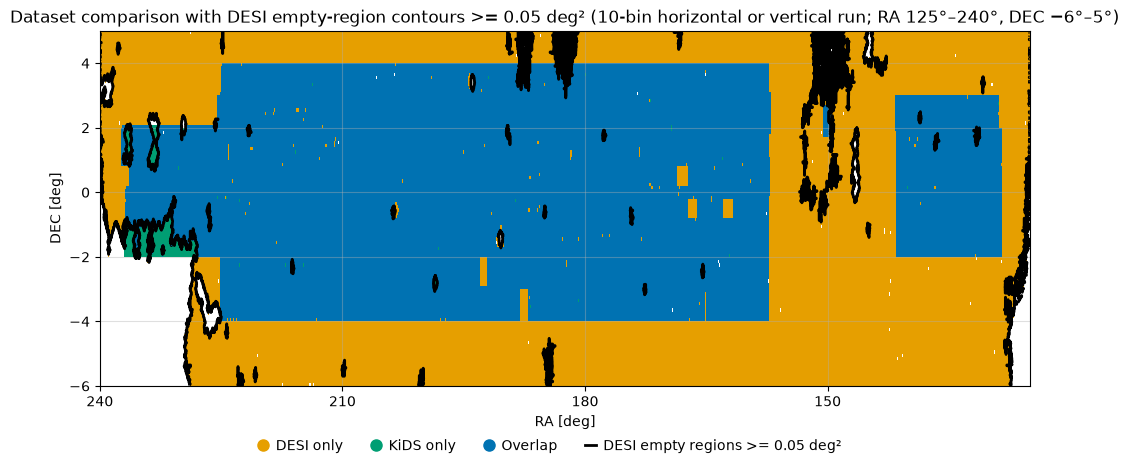

DESI-Empty-Regions konturiert (>= 0.05 deg²): 51
Non-empty bins im unveränderten Vergleichsplot: 120,609


In [76]:
desi_regions_to_contour = desi_regions_for_contour["region_id"].to_numpy()
desi_region_contour_mask = np.isin(desi_region_labels, desi_regions_to_contour)

desi_plot_ra_centers = (np.arange(desi_n_ra_bins) + 0.5) * desi_region_bin_size
desi_plot_dec_centers = (
    desi_plot_dec_min
    + (np.arange(desi_n_dec_bins) + 0.5) * desi_region_bin_size
)
desi_plot_ra_indices = np.flatnonzero(
    (desi_plot_ra_centers >= 125) & (desi_plot_ra_centers <= 240)
)
desi_plot_dec_indices = np.flatnonzero(
    (desi_plot_dec_centers >= -6) & (desi_plot_dec_centers <= 5)
)
desi_plot_contour = desi_region_contour_mask[
    np.ix_(desi_plot_ra_indices, desi_plot_dec_indices)
]

fig, ax = plt.subplots(figsize=(12, 5))
ax.pcolormesh(
    plot25_ra_edges,
    plot25_dec_edges,
    np.ma.masked_equal(plot25_zoom_comparison.T, 0),
    cmap=comparison_cmap,
    norm=comparison_norm,
    shading="auto",
)
if desi_plot_contour.any() and not desi_plot_contour.all():
    ax.contour(
        desi_plot_ra_centers[desi_plot_ra_indices],
        desi_plot_dec_centers[desi_plot_dec_indices],
        desi_plot_contour.T.astype(float),
        levels=[0.5],
        colors="black",
        linewidths=2.0,
        zorder=6,
    )

ax.set_xlim(240, 125)
ax.set_ylim(-6, 5)
ax.set_xticks(np.arange(240, 124, -30))
ax.set_xlabel("RA [deg]")
ax.set_ylabel("DEC [deg]")
ax.grid(True, alpha=0.4)
ax.set_title(
    "Dataset comparison with DESI empty-region contours "
    f">= {desi_region_area_threshold} deg² "
    "(10-bin horizontal or vertical run; RA 125°–240°, DEC −6°–5°)"
)
desi_plot_legend_items = legend_items + [
    Line2D(
        [],
        [],
        color="black",
        linewidth=2.0,
        label=f"DESI empty regions >= {desi_region_area_threshold} deg²",
    ),
]
fig.legend(
    handles=desi_plot_legend_items,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=4,
    frameon=False,
    handlelength=0.8,
    handletextpad=0.5,
)
fig.subplots_adjust(bottom=0.17)
plt.show()

print(f"DESI-Empty-Regions konturiert (>= {desi_region_area_threshold} deg²): {len(desi_regions_to_contour)}")
print(f"Non-empty bins im unveränderten Vergleichsplot: {np.count_nonzero(plot25_zoom_comparison):,}")

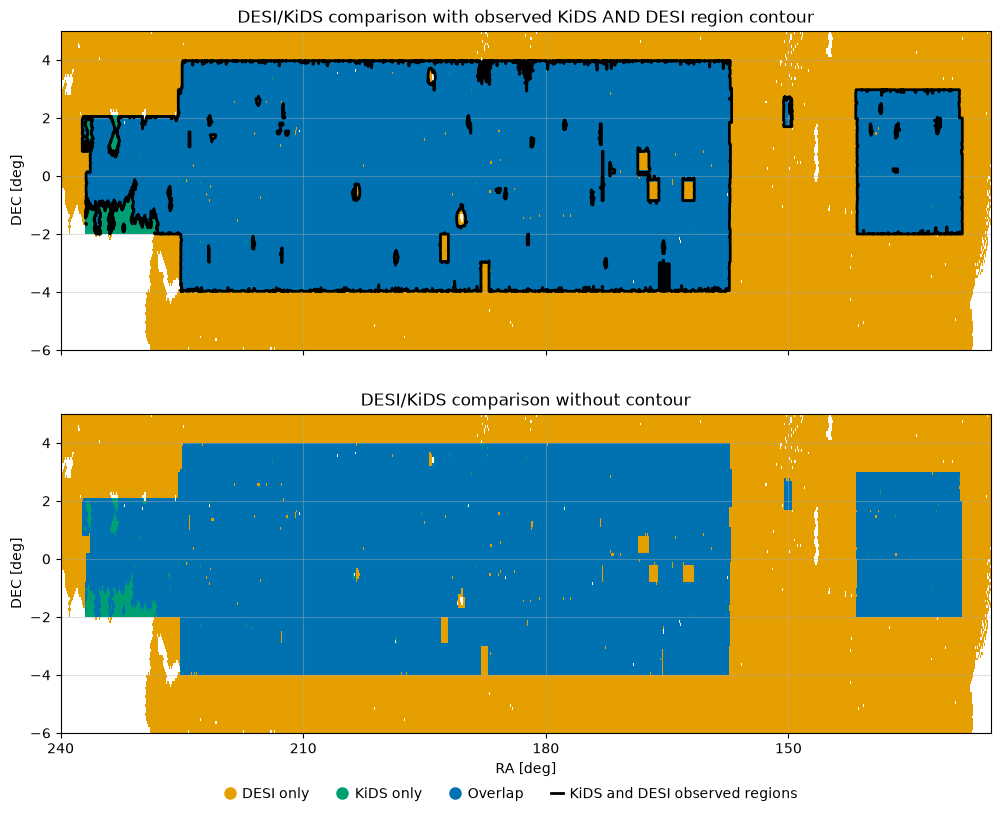

Vereinigte volle Kern-Bins: 1,011,432
Vereinigte Kernflaeche: 632.145000 deg²
Zusammenhaengende Regions der Vereinigung: 151


In [77]:
combined_full_region_core = ~(
    selected_empty_region_mask | desi_region_contour_mask
)

combined_region_labels, combined_region_count = label_regions(
    combined_full_region_core,
    structure=np.ones((3, 3), dtype=np.uint8),
)

combined_core_bin_count = int(np.count_nonzero(combined_full_region_core))

combined_core_area = combined_core_bin_count * full_bin_size**2

plot_combined_region_contour = combined_full_region_core[
    np.ix_(plot25_contour_ra_indices, plot25_contour_dec_indices)
]

fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 9),
    sharex=True,
    sharey=True,
)

for ax in axes:
    ax.pcolormesh(
        plot25_ra_edges,
        plot25_dec_edges,
        np.ma.masked_equal(plot25_zoom_comparison.T, 0),
        cmap=comparison_cmap,
        norm=comparison_norm,
        shading="auto",
    )

    ax.set_xlim(240, 125)
    ax.set_ylim(-6, 5)
    ax.set_xticks(np.arange(240, 124, -30))
    ax.set_ylabel("DEC [deg]")
    ax.grid(True, alpha=0.4)

if plot_combined_region_contour.any() and not plot_combined_region_contour.all():
    axes[0].contour(
        plot_ra_centers[plot25_contour_ra_indices],
        plot_dec_centers[plot25_contour_dec_indices],
        plot_combined_region_contour.T.astype(float),
        levels=[0.5],
        colors="black",
        linewidths=2.0,
        zorder=6,
    )

axes[0].set_title(
    "DESI/KiDS comparison with observed KiDS AND DESI region contour"
)

axes[1].set_title(
    "DESI/KiDS comparison without contour"
)

axes[1].set_xlabel("RA [deg]")

combined_plot_legend = legend_items + [
    Line2D(
        [],
        [],
        color="black",
        linewidth=2.0,
        label="KiDS and DESI observed regions",
    ),
]

fig.legend(
    handles=combined_plot_legend,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=4,
    frameon=False,
    handlelength=0.8,
    handletextpad=0.5,
)

fig.subplots_adjust(bottom=0.1, hspace=0.2)

plt.show()

print(f"Vereinigte volle Kern-Bins: {combined_core_bin_count:,}")
print(f"Vereinigte Kernflaeche: {combined_core_area:.6f} deg²")
print(
    f"Zusammenhaengende Regions der Vereinigung: "
    f"{max(combined_region_count - 1, 0)}"
)


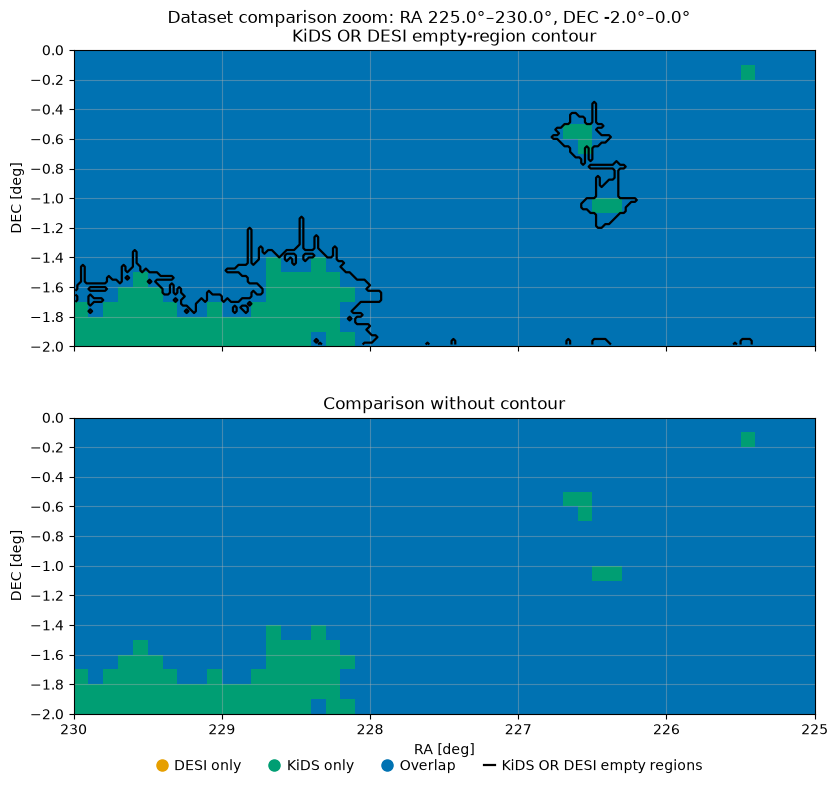

Comparison bins in zoom (0.1°): 1,000
KiDS OR DESI union-core bins in zoom (0.025°): 14,256


In [82]:
zoom_ra_min = 225.0
zoom_ra_max = 230.0
zoom_dec_min = -2.0
zoom_dec_max = 0.0

zoom_ra_indices = np.flatnonzero(
    (comparison_ra_as_degrees >= zoom_ra_min)
    & (comparison_ra_as_degrees <= zoom_ra_max)
)
zoom_dec_indices = np.flatnonzero(
    (comparison_dec_centers >= zoom_dec_min)
    & (comparison_dec_centers <= zoom_dec_max)
)
zoom_ra_edges = 180 - ra_bins[zoom_ra_indices[0]:zoom_ra_indices[-1] + 2]
zoom_dec_edges = dec_bins[zoom_dec_indices[0]:zoom_dec_indices[-1] + 2]
zoom_comparison = comparison[np.ix_(zoom_ra_indices, zoom_dec_indices)]

zoom_contour_ra_indices = np.flatnonzero(
    (plot_ra_centers >= zoom_ra_min) & (plot_ra_centers <= zoom_ra_max)
)
zoom_contour_dec_indices = np.flatnonzero(
    (plot_dec_centers >= zoom_dec_min) & (plot_dec_centers <= zoom_dec_max)
)
zoom_union_contour = combined_full_region_core[
    np.ix_(zoom_contour_ra_indices, zoom_contour_dec_indices)
]

fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 8),
    sharex=True,
    sharey=True,
)

for ax in axes:
    ax.pcolormesh(
        zoom_ra_edges,
        zoom_dec_edges,
        np.ma.masked_equal(zoom_comparison.T, 0),
        cmap=comparison_cmap,
        norm=comparison_norm,
        shading="auto",
    )
    ax.set_xlim(zoom_ra_max, zoom_ra_min)
    ax.set_ylim(zoom_dec_min, zoom_dec_max)
    ax.set_xticks(np.arange(zoom_ra_min, zoom_ra_max + 0.1, 1.0))
    ax.set_yticks(np.arange(zoom_dec_min, zoom_dec_max + 0.01, 0.2))
    ax.set_ylabel("DEC [deg]")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, alpha=0.4)

if zoom_union_contour.any() and not zoom_union_contour.all():
    axes[0].contour(
        plot_ra_centers[zoom_contour_ra_indices],
        plot_dec_centers[zoom_contour_dec_indices],
        zoom_union_contour.T.astype(float),
        levels=[0.5],
        colors="black",
        linewidths=1.6,
        zorder=6,
    )
else:
    axes[0].text(
        0.5,
        0.5,
        "Keine qualifizierende 10-Bin-Empty-Region\nin diesem Ausschnitt",
        transform=axes[0].transAxes,
        ha="center",
        va="center",
        color="white",
        bbox={"facecolor": "black", "alpha": 0.65, "edgecolor": "none"},
    )

axes[0].set_title("KiDS OR DESI empty-region contour")
axes[1].set_title("Comparison without contour")
axes[1].set_xlabel("RA [deg]")
zoom_legend_items = legend_items + [
    Line2D([], [], color="black", linewidth=1.6, label="KiDS OR DESI empty regions"),
]
fig.legend(
    handles=zoom_legend_items,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=4,
    frameon=False,
    handlelength=0.8,
    handletextpad=0.5,
)
fig.suptitle(
    f"Dataset comparison zoom: RA {zoom_ra_min}°–{zoom_ra_max}°, "
    f"DEC {zoom_dec_min}°–{zoom_dec_max}°"
)
fig.subplots_adjust(bottom=0.1, top=0.93, hspace=0.24)
plt.show()

print(f"Comparison bins in zoom (0.1°): {np.count_nonzero(zoom_comparison):,}")
print(f"KiDS OR DESI union-core bins in zoom (0.025°): {np.count_nonzero(zoom_union_contour):,}")

In [92]:
import json
import numpy as np

footprint_output_path = (
    "/home/rhoffmann/MA/Footprint/Overlap/"
    "kids_desi_full_region_union_0p025deg.npz"
)

# ---------------------------------------------------------
# Bin-Zentren des vollständigen Footprints
# ---------------------------------------------------------

ra_centers = (np.arange(n_ra_bins) + 0.5) * full_bin_size

dec_centers = (
    full_dec_min
    + (np.arange(n_dec_bins) + 0.5) * full_bin_size
)

# ---------------------------------------------------------
# Für jeden True-Bin die zugehörigen RA/DEC-Zentren bestimmen
# ---------------------------------------------------------

true_ra_indices, true_dec_indices = np.where(
    combined_full_region_core
)

ra_deg = ra_centers[true_ra_indices]
dec_deg = dec_centers[true_dec_indices]

# ---------------------------------------------------------
# Metadaten
# ---------------------------------------------------------

metadata = {
    "description": "KiDS AND DESI observed/full region",
    "bin_size_deg": float(full_bin_size),
    "n_ra_bins": int(n_ra_bins),
    "n_dec_bins": int(n_dec_bins),
    "full_dec_min": float(full_dec_min),
    "full_dec_max": float(full_dec_max),
    "n_true_bins": int(np.count_nonzero(combined_full_region_core)),
}

# ---------------------------------------------------------
# Speichern
# ---------------------------------------------------------

np.savez(
    footprint_output_path,
    ra_deg=ra_deg,
    dec_deg=dec_deg,
    footprint_mask=combined_full_region_core,
    metadata_json=json.dumps(metadata),
)

print(f"Footprint erfolgreich gespeichert: {footprint_output_path}")
print(f"Shape: {combined_full_region_core.shape}")
print(f"True-Bins: {np.count_nonzero(combined_full_region_core):,}")
print(f"Gespeicherte RA/DEC-Paare: {len(ra_deg):,}")

Footprint erfolgreich gespeichert: /home/rhoffmann/MA/Footprint/Overlap/kids_desi_full_region_union_0p025deg.npz
Shape: (14400, 440)
True-Bins: 1,011,432
Gespeicherte RA/DEC-Paare: 1,011,432


In [93]:
print(combined_full_region_core)

[[False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]
 ...
 [False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]]


In [94]:
import json

with np.load(footprint_output_path, allow_pickle=False) as saved_footprint:
    footprint_ra_deg_saved = saved_footprint["ra_deg"]
    footprint_dec_deg_saved = saved_footprint["dec_deg"]
    footprint_mask_saved = saved_footprint["footprint_mask"]
    footprint_metadata_saved = json.loads(str(saved_footprint["metadata_json"]))

assert len(footprint_ra_deg_saved) == len(footprint_dec_deg_saved)
assert len(footprint_ra_deg_saved) == np.count_nonzero(footprint_mask_saved)
assert np.array_equal(footprint_mask_saved, combined_full_region_core)

print(f"NPZ erfolgreich geladen und geprueft: {len(footprint_ra_deg_saved):,} RA/DEC-Paare")
print(f"Metadaten: {footprint_metadata_saved}")
print("Koordinaten stehen in footprint_ra_deg_saved und footprint_dec_deg_saved bereit.")

NPZ erfolgreich geladen und geprueft: 1,011,432 RA/DEC-Paare
Metadaten: {'description': 'KiDS AND DESI observed/full region', 'bin_size_deg': 0.025, 'n_ra_bins': 14400, 'n_dec_bins': 440, 'full_dec_min': -6.0, 'full_dec_max': 5.0, 'n_true_bins': 1011432}
Koordinaten stehen in footprint_ra_deg_saved und footprint_dec_deg_saved bereit.
